# Modeling Cognitive Overload and Alert Fatigue in SOC Alert Streams Using CIC-IDS2017

This Google Colab notebook treats CIC-IDS2017 attack-labeled network flows as a **proxy SOC alert stream**. It simulates alert-load conditions, derives workload proxy features, compares a baseline SOC workflow against an adaptive SOC workflow, and applies machine learning models for workload-level prediction and missed-critical-alert risk prediction.

**Important research note:** CIC-IDS2017 is not a native SOC alert log. In this notebook, attack-labeled flows are used as simulated alert-generating events, while benign flows represent normal or background traffic. The resulting workload score is a simulation-based proxy and not a direct measurement of human cognitive load.


**Version 11 corrections.**
1. CIC-IDS2017 `TrafficLabelling` timestamps use a 12-hour clock without AM/PM; hours 1-7 are shifted to 13:00-19:59.
2. Seven of the eight files record time only to the minute, so the aggregation window is 60 seconds (30-second windows alternated between populated and structurally empty windows).
3. Adaptive first-critical ranks are undefined (not 0) in windows without simulated critical alerts.
4. An alert-level review-budget variant of the adaptive workflow is reported next to the group-level variant.
5. Next-window prediction uses only pairs of consecutive active windows.
6. Timestamp ties are broken by a seeded random permutation, so synthetic background and duplicate alerts are interleaved with attack-derived alerts in the chronological baseline.
7. Critical-window summaries, a persistence baseline for the missed-risk task, and `paper_numbers.json` are exported.


## 1. Setup

This section installs missing packages if needed, imports the main libraries, and defines reusable helpers.

Colab tips:
- Prefer the `TrafficLabelling` CSV files when you want real timestamps.
- In free Colab, upload the CIC-IDS2017 files in **small batches** rather than selecting all 8 files at once.
- The notebook now defaults to a memory-safe path that keeps only the columns needed for this research pipeline.
- If you upload very large files, start with 1 file first to verify the full pipeline.


In [1]:
# Install required packages when they are missing.
import importlib
import subprocess
import sys

REQUIRED_PACKAGES = {
    "pandas": "pandas",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "sklearn": "scikit-learn",
}
# gdown is only needed for the optional Google Drive download mode.
OPTIONAL_PACKAGES = {
    "xgboost": "xgboost",
}

def ensure_package(module_name, package_name):
    try:
        importlib.import_module(module_name)
        return True
    except ImportError:
        print(f"Installing missing package: {package_name}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package_name])
        importlib.import_module(module_name)
        return True

for module_name, package_name in REQUIRED_PACKAGES.items():
    ensure_package(module_name, package_name)

# The reported run uses the scikit-learn models only, so it does not depend on
# XGBoost. Set USE_XGBOOST = True to add it as an exploratory extra model.
USE_XGBOOST = False
HAS_XGBOOST = False
if USE_XGBOOST:
    try:
        HAS_XGBOOST = ensure_package("xgboost", OPTIONAL_PACKAGES["xgboost"])
    except Exception as exc:
        print(f"XGBoost could not be installed. Continuing without it. Details: {exc}")
        HAS_XGBOOST = False


In [2]:
import gc
import io
import os
import re
import shutil
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler

if HAS_XGBOOST:
    from xgboost import XGBClassifier

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (12, 6)

OUTPUT_DIR = Path("exported_results")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_PATHS = []

MEMORY_SAFE_UPLOAD = True
MAX_ANALYSIS_ROWS = 50_000
CICIDS2017_12H_CLOCK_FIX = True
DATA_SOURCE_MODE = "local_workspace"
SHARED_DRIVE_FOLDER_URL = ""
MOUNTED_DRIVE_FOLDER = "/content/drive/MyDrive/TrafficLabelling"
LOCAL_SHARED_FOLDER = Path("/content/TrafficLabelling_shared")

OPTIONAL_NUMERIC_FEATURES = [
    "Flow Duration",
    "Flow Bytes/s",
    "Flow Packets/s",
    "Total Fwd Packets",
    "Total Backward Packets",
    "Packet Length Mean",
    "Packet Length Std",
    "Average Packet Size",
    "Flow IAT Mean",
    "Flow IAT Std",
    "Flow IAT Max",
    "Flow IAT Min",
    "Active Mean",
    "Idle Mean",
]

OPTIONAL_CATEGORICAL_FEATURES = [
    "Source IP",
    "Destination IP",
    "Source Port",
    "Destination Port",
    "Protocol",
]

CANONICAL_LABEL_MAP = {
    "BENIGN": "BENIGN",
    "DDOS": "DDoS",
    "DOS HULK": "DoS Hulk",
    "DOS GOLDENEYE": "DoS GoldenEye",
    "DOS SLOWLORIS": "DoS slowloris",
    "DOS SLOWHTTPTEST": "DoS Slowhttptest",
    "HEARTBLEED": "Heartbleed",
    "INFILTRATION": "Infiltration",
    "INFILTERATION": "Infiltration",
    "PORTSCAN": "PortScan",
    "BOT": "Bot",
    "FTP PATATOR": "FTP-Patator",
    "FTP PATATOR ATTACK": "FTP-Patator",
    "SSH PATATOR": "SSH-Patator",
    "WEB ATTACK BRUTE FORCE": "Web Attack - Brute Force",
    "WEB ATTACK BRUTEFORCE": "Web Attack - Brute Force",
    "WEB ATTACK XSS": "Web Attack - XSS",
    "WEB ATTACK SQL INJECTION": "Web Attack - Sql Injection",
    "WEB ATTACK SQLINJECTION": "Web Attack - Sql Injection",
}

def save_current_figure(filename):
    output_path = OUTPUT_DIR / filename
    plt.tight_layout()
    plt.savefig(output_path, dpi=300, bbox_inches="tight")
    FIGURE_PATHS.append(str(output_path))
    print(f"Saved figure: {output_path}")

def normalize_text(value):
    value = "" if value is None else str(value)
    value = value.strip().lower()
    value = re.sub(r"[^a-z0-9]+", "", value)
    return value

def normalize_label_key(value):
    value = "" if value is None else str(value)
    value = value.strip().upper()
    value = value.replace("\x96", " ")
    value = re.sub(r"[^A-Z0-9]+", " ", value).strip()
    value = re.sub(r"\s+", " ", value).strip()
    return value

def canonicalize_label(value):
    if pd.isna(value):
        return pd.NA

    raw_value = str(value).strip()
    normalized = normalize_label_key(raw_value)

    if normalized in {"", "NAN", "NONE", "NULL", "NA", "<NA>"}:
        return pd.NA

    if normalized in CANONICAL_LABEL_MAP:
        return CANONICAL_LABEL_MAP[normalized]

    if normalized.startswith("WEB ATTACK"):
        if "BRUTE" in normalized:
            return "Web Attack - Brute Force"
        if "SQL" in normalized:
            return "Web Attack - Sql Injection"
        if "XSS" in normalized:
            return "Web Attack - XSS"

    return raw_value

def find_label_column(columns):
    candidates = []
    for column in columns:
        normalized = normalize_text(column)
        if normalized in {"label", "labels", "class", "attacklabel", "attacktype", "category"}:
            candidates.append(column)
        elif "label" in normalized or normalized == "class":
            candidates.append(column)
    return candidates[0] if candidates else None

def find_timestamp_column(columns):
    exact_candidates = {"timestamp", "time", "datetime", "flowstarttime", "starttime", "date"}
    for column in columns:
        normalized = normalize_text(column)
        if normalized in exact_candidates:
            return column
    for column in columns:
        normalized = normalize_text(column)
        if "timestamp" in normalized or normalized.endswith("datetime") or normalized.endswith("starttime"):
            return column
    return None

def parse_timestamp_series(series):
    """Parse CIC-IDS2017 timestamps without cross-file format inference."""
    cleaned = pd.Series(series, copy=False).astype("string").str.strip()
    cleaned = cleaned.replace({"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA})
    parsed = pd.Series(pd.NaT, index=cleaned.index, dtype="datetime64[ns]")
    # CIC-IDS2017 uses day/month/year and contains both minute and second values.
    for timestamp_format in ("%d/%m/%Y %H:%M:%S", "%d/%m/%Y %H:%M"):
        parsed = parsed.fillna(pd.to_datetime(cleaned, format=timestamp_format, errors="coerce"))
    # Retain a mixed parser only as a fallback for a compatible user-provided file.
    try:
        parsed = parsed.fillna(pd.to_datetime(cleaned, format="mixed", dayfirst=True, errors="coerce"))
    except (TypeError, ValueError):
        parsed = parsed.fillna(pd.to_datetime(cleaned, dayfirst=True, errors="coerce"))
    if CICIDS2017_12H_CLOCK_FIX:
        # TrafficLabelling timestamps use a 12-hour clock without an AM/PM marker.
        # Capture ran from about 08:55 to 17:05 each day, so hours 1-7 are afternoon
        # times (13:00-19:59) and are shifted forward by 12 hours.
        afternoon = parsed.dt.hour.between(1, 7)
        parsed = parsed.where(~afternoon, parsed + pd.Timedelta(hours=12))
    return parsed

def safe_mode(series, fallback="NO_ATTACK"):
    non_null = series.dropna()
    if non_null.empty:
        return fallback
    mode_values = non_null.mode()
    return mode_values.iloc[0] if not mode_values.empty else non_null.iloc[0]

def safe_minmax(series):
    numeric_series = pd.to_numeric(series, errors="coerce")
    min_value = numeric_series.min()
    max_value = numeric_series.max()
    if pd.isna(min_value) or pd.isna(max_value) or max_value == min_value:
        return pd.Series(0.0, index=series.index, dtype="float64")
    return ((numeric_series - min_value) / (max_value - min_value)).fillna(0.0)

def safe_nunique(frame, column):
    if column not in frame.columns:
        return 0
    series = frame[column].dropna()
    return int(series.nunique()) if not series.empty else 0

def safe_numeric_stat(frame, column, stat="mean"):
    if column not in frame.columns:
        return 0.0

    series = (
        pd.to_numeric(frame[column], errors="coerce")
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    if series.empty:
        return 0.0

    if stat == "mean":
        return float(series.mean())
    if stat == "median":
        return float(series.median())
    if stat == "max":
        return float(series.max())
    if stat == "std":
        return float(series.std())

    raise ValueError(f"Unsupported stat: {stat}")

def safe_top_share(series):
    non_null = series.dropna()
    if non_null.empty:
        return 0.0
    counts = non_null.value_counts()
    return float(counts.iloc[0] / counts.sum())

def downcast_numeric_types(df):
    for column in df.select_dtypes(include=["float64"]).columns:
        df[column] = pd.to_numeric(df[column], downcast="float")
    for column in df.select_dtypes(include=["int64"]).columns:
        df[column] = pd.to_numeric(df[column], downcast="integer")
    return df

def choose_stratify_target(target_series):
    counts = pd.Series(target_series).value_counts()
    if counts.empty or counts.min() < 2 or counts.shape[0] < 2:
        return None
    return target_series

def get_positive_scores(model, features):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(features)[:, 1]

    if hasattr(model, "decision_function"):
        raw_scores = np.asarray(model.decision_function(features), dtype="float64")
        return safe_minmax(pd.Series(raw_scores)).to_numpy()

    return None

def safe_binary_roc_auc(y_true, y_score):
    if y_score is None or pd.Series(y_true).nunique() < 2:
        return np.nan
    return roc_auc_score(y_true, y_score)

def safe_binary_average_precision(y_true, y_score):
    if y_score is None or pd.Series(y_true).nunique() < 2:
        return np.nan
    return average_precision_score(y_true, y_score)

def needs_binary_rebalance(y_train, y_test, min_positive_cases=20):
    y_train = pd.Series(y_train)
    y_test = pd.Series(y_test)
    return (
        y_train.nunique() < 2
        or y_test.nunique() < 2
        or int(y_train.sum()) < min_positive_cases
        or int(y_test.sum()) < min_positive_cases
    )

def needs_multiclass_rebalance(y_train, y_test, all_labels, min_class_cases=10):
    train_counts = pd.Series(y_train).value_counts().reindex(all_labels, fill_value=0)
    test_counts = pd.Series(y_test).value_counts().reindex(all_labels, fill_value=0)
    return (
        train_counts.eq(0).any()
        or test_counts.eq(0).any()
        or int(test_counts.min()) < min_class_cases
    )

def assign_active_load_level(percentile_value):
    if percentile_value <= 0.40:
        return "Low"
    if percentile_value <= 0.70:
        return "Moderate"
    if percentile_value <= 0.90:
        return "High"
    return "Burst"

def compute_alert_review_budget(alert_count, load_level=None):
    if alert_count <= 0:
        return 0

    inferred_level = load_level
    if inferred_level is None:
        if alert_count >= 3000:
            inferred_level = "Burst"
        elif alert_count >= 250:
            inferred_level = "High"
        elif alert_count >= 60:
            inferred_level = "Moderate"
        else:
            inferred_level = "Low"

    if inferred_level == "Burst":
        return int(max(4, min(8, np.ceil(alert_count * 0.01))))
    if inferred_level == "High":
        return int(max(5, min(10, np.ceil(alert_count * 0.02))))
    if inferred_level == "Moderate":
        return int(max(6, min(14, np.ceil(alert_count * 0.05))))
    return int(max(5, min(18, np.ceil(alert_count * 0.08))))

def select_relevant_columns(available_columns):
    timestamp_column = find_timestamp_column(available_columns)
    label_column = find_label_column(available_columns)
    if label_column is None:
        raise ValueError("A label column could not be detected in one of the loaded CSV files.")

    selected_columns = []
    if timestamp_column is not None:
        selected_columns.append(timestamp_column)
    selected_columns.append(label_column)

    for candidate in OPTIONAL_CATEGORICAL_FEATURES + OPTIONAL_NUMERIC_FEATURES:
        if candidate in available_columns:
            selected_columns.append(candidate)

    selected_columns = list(dict.fromkeys(selected_columns))
    return selected_columns, timestamp_column, label_column

def make_dtype_map(selected_columns, timestamp_column, label_column):
    dtype_map = {}
    for column in selected_columns:
        if column == timestamp_column:
            dtype_map[column] = "string"
        elif column == label_column:
            dtype_map[column] = "string"
        elif column in OPTIONAL_CATEGORICAL_FEATURES:
            dtype_map[column] = "string"
        elif column in OPTIONAL_NUMERIC_FEATURES:
            dtype_map[column] = "float32"
    return dtype_map

def build_memory_safe_frame_from_bytes(file_bytes):
    try:
        raw_header_df = pd.read_csv(io.BytesIO(file_bytes), nrows=0)
    except UnicodeDecodeError:
        raw_header_df = pd.read_csv(io.BytesIO(file_bytes), nrows=0, encoding="latin1")

    original_columns = [col for col in raw_header_df.columns]
    stripped_columns = [col.strip() if isinstance(col, str) else col for col in original_columns]
    stripped_to_original_map = {
        stripped: original for stripped, original in zip(stripped_columns, original_columns)
    }

    selected_stripped_columns, timestamp_stripped, label_stripped = select_relevant_columns(
        stripped_columns
    )
    selected_original_columns = [stripped_to_original_map[s_col] for s_col in selected_stripped_columns]

    dtype_map = make_dtype_map(selected_stripped_columns, timestamp_stripped, label_stripped)
    dtype_map = {stripped_to_original_map[column]: dtype for column, dtype in dtype_map.items()}

    read_kwargs = {
        "usecols": selected_original_columns,
        "low_memory": True,
        "dtype": dtype_map,
    }

    try:
        file_df = pd.read_csv(io.BytesIO(file_bytes), **read_kwargs)
    except UnicodeDecodeError:
        file_df = pd.read_csv(io.BytesIO(file_bytes), encoding="latin1", **read_kwargs)

    file_df.columns = [column.strip() if isinstance(column, str) else column for column in file_df.columns]
    return file_df, timestamp_stripped, label_stripped

def build_memory_safe_frame_from_path(csv_path):
    try:
        raw_header_df = pd.read_csv(csv_path, nrows=0)
    except UnicodeDecodeError:
        raw_header_df = pd.read_csv(csv_path, nrows=0, encoding="latin1")

    original_columns = [col for col in raw_header_df.columns]
    stripped_columns = [col.strip() if isinstance(col, str) else col for col in original_columns]
    stripped_to_original_map = {
        stripped: original for stripped, original in zip(stripped_columns, original_columns)
    }

    selected_stripped_columns, timestamp_stripped, label_stripped = select_relevant_columns(
        stripped_columns
    )
    selected_original_columns = [stripped_to_original_map[s_col] for s_col in selected_stripped_columns]

    dtype_map = make_dtype_map(selected_stripped_columns, timestamp_stripped, label_stripped)
    dtype_map = {stripped_to_original_map[column]: dtype for column, dtype in dtype_map.items()}

    read_kwargs = {
        "usecols": selected_original_columns,
        "low_memory": True,
        "dtype": dtype_map,
    }

    try:
        file_df = pd.read_csv(csv_path, **read_kwargs)
    except UnicodeDecodeError:
        file_df = pd.read_csv(csv_path, encoding="latin1", **read_kwargs)

    file_df.columns = [column.strip() if isinstance(column, str) else column for column in file_df.columns]
    return file_df, timestamp_stripped, label_stripped

def summarize_dataframe_memory(df, label):
    memory_mb = df.memory_usage(deep=True).sum() / (1024 ** 2)
    print(f"{label} memory usage: {memory_mb:.2f} MB")

def list_csv_files(root_dir):
    root_dir = Path(root_dir)
    return sorted([path for path in root_dir.rglob("*.csv") if path.is_file()])

def resolve_shared_drive_csv_paths():
    import gdown

    LOCAL_SHARED_FOLDER.mkdir(parents=True, exist_ok=True)
    csv_paths = list_csv_files(LOCAL_SHARED_FOLDER)

    if not csv_paths:
        print("Downloading the shared Google Drive folder to local Colab storage...")
        gdown.download_folder(
            url=SHARED_DRIVE_FOLDER_URL,
            output=str(LOCAL_SHARED_FOLDER),
            quiet=False,
            use_cookies=False,
        )
        csv_paths = list_csv_files(LOCAL_SHARED_FOLDER)

    if not csv_paths:
        raise FileNotFoundError(
            "No CSV files were found after downloading the shared Google Drive folder."
        )
    return csv_paths

def resolve_mounted_drive_csv_paths():
    from google.colab import drive

    drive.mount("/content/drive")
    csv_paths = list_csv_files(MOUNTED_DRIVE_FOLDER)
    if not csv_paths:
        raise FileNotFoundError(
            "No CSV files were found in the mounted Drive folder. "
            "Update MOUNTED_DRIVE_FOLDER if your TrafficLabelling path is different."
        )
    return csv_paths

def make_model_dict(task_type, num_classes=None):
    models = {
        "Logistic Regression": Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                (
                    "model",
                    LogisticRegression(
                        max_iter=2000,
                        random_state=SEED,
                        class_weight="balanced" if task_type == "binary" else None,
                    ),
                ),
            ]
        ),
        "Random Forest": RandomForestClassifier(
            n_estimators=300,
            random_state=SEED,
            class_weight="balanced" if task_type == "binary" else None,
            n_jobs=-1,
        ),
        "Gradient Boosting": Pipeline(
            [
                ("imputer", SimpleImputer(strategy="median")),
                ("model", GradientBoostingClassifier(random_state=SEED)),
            ]
        ),
    }

    if HAS_XGBOOST:
        if task_type == "multiclass":
            models["XGBoost"] = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    (
                        "model",
                        XGBClassifier(
                            n_estimators=300,
                            max_depth=5,
                            learning_rate=0.05,
                            subsample=0.9,
                            colsample_bytree=0.9,
                            random_state=SEED,
                            objective="multi:softprob",
                            eval_metric="mlogloss",
                            num_class=num_classes,
                        ),
                    ),
                ]
            )
        else:
            models["XGBoost"] = Pipeline(
                [
                    ("imputer", SimpleImputer(strategy="median")),
                    (
                        "model",
                        XGBClassifier(
                            n_estimators=300,
                            max_depth=5,
                            learning_rate=0.05,
                            subsample=0.9,
                            colsample_bytree=0.9,
                            random_state=SEED,
                            objective="binary:logistic",
                            eval_metric="logloss",
                        ),
                    ),
                ]
            )
    return models

print(f"Output directory: {OUTPUT_DIR}")
print(f"XGBoost available: {HAS_XGBOOST}")
print(f"Memory-safe upload mode: {MEMORY_SAFE_UPLOAD}")
print(f"Data source mode: {DATA_SOURCE_MODE}")
print(f"Shared Drive folder URL: {SHARED_DRIVE_FOLDER_URL}")

Output directory: exported_results
XGBoost available: False
Memory-safe upload mode: True
Data source mode: local_workspace
Shared Drive folder URL: 


## 2. Dataset Access

Browser upload is not recommended for the full `TrafficLabelling` set in free Colab because it often exhausts RAM before analysis begins.

This notebook supports four data-source modes:
- `local_workspace` (default):
  reads the CSVs from `./TrafficLabelling`
- `gdown_folder_url`:
  downloads the shared Google Drive folder directly to Colab storage and reads the CSVs from disk
- `mounted_drive`:
  mounts your own Google Drive and reads CSVs from a Drive path
- `files_upload`:
  keeps the old browser-upload option for very small test runs only

The default mode is `local_workspace`, which reads the CSV files from `./TrafficLabelling`. Set `SHARED_DRIVE_FOLDER_URL` or `FOLDER_ID` only if you use the Google Drive modes.


In [3]:
# Load CIC-IDS2017 CSV files from Google Drive with a safe fallback.
# Recommended: add the TrafficLabelling folder to your own Google Drive first,
# then point DRIVE_TRAFFICLABELLING_DIR to it.

loaded_frames = []
load_log = []

FOLDER_ID = ""  # set to your own Google Drive folder ID if using gdown
DRIVE_TRAFFICLABELLING_DIR = "/content/drive/MyDrive/TrafficLabelling"
LOCAL_SHARED_FOLDER = Path("/content/TrafficLabelling_shared")
LOCAL_DRIVE_CACHE = Path("/content/TrafficLabelling_drive_cache")

def materialize_csvs_locally(source_paths, cache_dir):
    cache_dir.mkdir(parents=True, exist_ok=True)
    local_paths = []

    for source_path in source_paths:
        source_path = Path(source_path)
        local_path = cache_dir / source_path.name

        try:
            source_size = source_path.stat().st_size
        except OSError:
            source_size = None

        needs_copy = True
        if local_path.exists():
            if source_size is None:
                needs_copy = False
            else:
                try:
                    needs_copy = local_path.stat().st_size != source_size
                except OSError:
                    needs_copy = True

        if needs_copy:
            print(f"Copying {source_path.name} to local Colab storage...")
            shutil.copy2(source_path, local_path)

        local_paths.append(local_path)

    return local_paths

csv_paths = []
data_source_used = None
if DATA_SOURCE_MODE == "local_workspace":
    csv_paths = list_csv_files(Path("TrafficLabelling"))
    data_source_used = "local_workspace"
    if not csv_paths:
        raise FileNotFoundError("No CIC-IDS2017 CSV files found in ./TrafficLabelling")

if DATA_SOURCE_MODE == "gdown_folder_url":
    try:
        print("Trying shared Google Drive folder download first...")
        csv_paths = resolve_shared_drive_csv_paths()
        data_source_used = "shared_folder_download"
    except Exception as exc:
        print(f"Shared-folder download did not succeed: {exc}")

if not csv_paths:
    try:
        from google.colab import drive

        drive.mount("/content/drive", force_remount=False)

        candidate_dirs = [
            Path(DRIVE_TRAFFICLABELLING_DIR),
            Path("/content/drive/MyDrive/TrafficLabelling"),
            Path("/content/drive/Shareddrives/TrafficLabelling"),
        ]

        for candidate_dir in candidate_dirs:
            if candidate_dir.exists():
                drive_csv_paths = list_csv_files(candidate_dir)
                if drive_csv_paths:
                    print(f"Using Drive folder: {candidate_dir}")
                    print("Copying Drive CSV files to local Colab storage before reading...")
                    csv_paths = materialize_csvs_locally(drive_csv_paths, LOCAL_DRIVE_CACHE)
                    data_source_used = "mounted_drive_local_cache"
                    break
    except Exception as exc:
        print(f"Drive mount check skipped: {exc}")

if not csv_paths:
    import gdown

    LOCAL_SHARED_FOLDER.mkdir(parents=True, exist_ok=True)
    try:
        print("Trying shared Google Drive folder download by folder ID...")
        gdown.download_folder(
            id=FOLDER_ID,
            output=str(LOCAL_SHARED_FOLDER),
            quiet=False,
            use_cookies=False,
            remaining_ok=True,
        )
        csv_paths = list_csv_files(LOCAL_SHARED_FOLDER)
        data_source_used = "folder_id_download"
    except Exception as exc:
        raise RuntimeError(
            "Could not access the shared folder with gdown or a mounted Drive copy. "
            "Add the TrafficLabelling folder to your own Google Drive, then set "
            "DRIVE_TRAFFICLABELLING_DIR to that folder and rerun this cell."
        ) from exc

if not csv_paths:
    raise FileNotFoundError(
        "No CSV files were found. "
        "Put TrafficLabelling in your Google Drive and update DRIVE_TRAFFICLABELLING_DIR."
    )

print(f"Data source used: {data_source_used}")
print(f"Found {len(csv_paths)} CSV files.")

for csv_path in csv_paths:
    try:
        file_df, file_timestamp_column, file_label_column = build_memory_safe_frame_from_path(csv_path)
    except OSError as exc:
        raise RuntimeError(
            f"Failed while reading {csv_path.name}. "
            "If this came from mounted Drive, restart the Colab runtime and rerun so the files "
            "are recopied into local storage."
        ) from exc

    file_df["source_file"] = csv_path.name
    loaded_frames.append(file_df)

    load_log.append(
        {
            "file_name": csv_path.name,
            "rows": file_df.shape[0],
            "columns": file_df.shape[1],
            "timestamp_column": file_timestamp_column,
            "label_column": file_label_column,
        }
    )

    summarize_dataframe_memory(file_df, f"Loaded frame for {csv_path.name}")
    gc.collect()

combined_df = (
    pd.concat(loaded_frames, ignore_index=True, copy=False)
    if len(loaded_frames) > 1
    else loaded_frames[0]
)
del loaded_frames
gc.collect()

combined_df.columns = [column.strip() if isinstance(column, str) else column for column in combined_df.columns]

detected_timestamp_column = find_timestamp_column(combined_df.columns)
detected_label_column = find_label_column(combined_df.columns)

print("Load summary:")
display(pd.DataFrame(load_log))

print(f"Combined dataset shape: {combined_df.shape}")
print(f"Detected timestamp column: {detected_timestamp_column}")
print(f"Detected label column: {detected_label_column}")
print("Column names kept in memory:")
print(list(combined_df.columns))
summarize_dataframe_memory(combined_df, "Combined dataframe")

if detected_label_column is not None:
    print("Label distribution:")
    display(
        combined_df[detected_label_column]
        .astype(str)
        .str.strip()
        .value_counts(dropna=False)
        .to_frame("count")
    )
else:
    print("Warning: No label column was detected yet.")


Data source used: local_workspace
Found 8 CSV files.
Loaded frame for Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv memory usage: 117.48 MB
Loaded frame for Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv memory usage: 151.20 MB
Loaded frame for Friday-WorkingHours-Morning.pcap_ISCX.csv memory usage: 98.83 MB
Loaded frame for Monday-WorkingHours.pcap_ISCX.csv memory usage: 272.87 MB
Loaded frame for Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv memory usage: 154.12 MB
Loaded frame for Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv memory usage: 241.95 MB
Loaded frame for Tuesday-WorkingHours.pcap_ISCX.csv memory usage: 227.59 MB
Loaded frame for Wednesday-workingHours.pcap_ISCX.csv memory usage: 354.91 MB
Load summary:


,file_name,rows,columns,timestamp_column,label_column
0,Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv,225745,22,Timestamp,Label
1,Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv,286467,22,Timestamp,Label
2,Friday-WorkingHours-Morning.pcap_ISCX.csv,191033,22,Timestamp,Label
3,Monday-WorkingHours.pcap_ISCX.csv,529918,22,Timestamp,Label
4,Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv,288602,22,Timestamp,Label
5,Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv,458968,22,Timestamp,Label
6,Tuesday-WorkingHours.pcap_ISCX.csv,445909,22,Timestamp,Label
7,Wednesday-workingHours.pcap_ISCX.csv,692703,22,Timestamp,Label


Combined dataset shape: (3119345, 22)
Detected timestamp column: Timestamp
Detected label column: Label
Column names kept in memory:
['Source IP', 'Source Port', 'Destination IP', 'Destination Port', 'Protocol', 'Timestamp', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Packet Length Mean', 'Packet Length Std', 'Average Packet Size', 'Active Mean', 'Idle Mean', 'Label', 'source_file']
Combined dataframe memory usage: 1618.95 MB
Label distribution:


,count
Label,
BENIGN,2273097
NaN,288602
DoS Hulk,231073
PortScan,158930
DDoS,128027
DoS GoldenEye,10293
FTP-Patator,7938
SSH-Patator,5897
DoS slowloris,5796


In [4]:
print(f"Inspecting columns of the first CSV file: {csv_paths[0].name}")

try:
    # Read only the header to get column names
    header_df = pd.read_csv(csv_paths[0], nrows=0)
except UnicodeDecodeError:
    header_df = pd.read_csv(csv_paths[0], nrows=0, encoding="latin1")

# Strip whitespace from column names for better comparison
header_df.columns = [col.strip() for col in header_df.columns]

print("Actual column names in the first CSV file:")
for col in header_df.columns:
    print(f"- '{col}'")


Inspecting columns of the first CSV file: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Actual column names in the first CSV file:
- 'Flow ID'
- 'Source IP'
- 'Source Port'
- 'Destination IP'
- 'Destination Port'
- 'Protocol'
- 'Timestamp'
- 'Flow Duration'
- 'Total Fwd Packets'
- 'Total Backward Packets'
- 'Total Length of Fwd Packets'
- 'Total Length of Bwd Packets'
- 'Fwd Packet Length Max'
- 'Fwd Packet Length Min'
- 'Fwd Packet Length Mean'
- 'Fwd Packet Length Std'
- 'Bwd Packet Length Max'
- 'Bwd Packet Length Min'
- 'Bwd Packet Length Mean'
- 'Bwd Packet Length Std'
- 'Flow Bytes/s'
- 'Flow Packets/s'
- 'Flow IAT Mean'
- 'Flow IAT Std'
- 'Flow IAT Max'
- 'Flow IAT Min'
- 'Fwd IAT Total'
- 'Fwd IAT Mean'
- 'Fwd IAT Std'
- 'Fwd IAT Max'
- 'Fwd IAT Min'
- 'Bwd IAT Total'
- 'Bwd IAT Mean'
- 'Bwd IAT Std'
- 'Bwd IAT Max'
- 'Bwd IAT Min'
- 'Fwd PSH Flags'
- 'Bwd PSH Flags'
- 'Fwd URG Flags'
- 'Bwd URG Flags'
- 'Fwd Header Length'
- 'Bwd Header Length'
- 'Fwd Packets/s'
- 'Bwd Pack

## 3. Data Cleaning

This section standardizes key fields, converts timestamps, handles missing or infinite values, and creates a binary attack indicator:
- `BENIGN` -> `is_attack = 0`
- any other label -> `is_attack = 1`

If no timestamp column is present, the notebook creates a **synthetic timestamp** using row order so the rest of the time-window pipeline can still run. This is useful for the timestamp-free `MachineLearningCVE` files, but the `TrafficLabelling` files remain the preferred research input.


In [5]:
# Clean the uploaded data with minimal copying to reduce RAM usage.
analysis_df = combined_df

timestamp_column = find_timestamp_column(analysis_df.columns)
label_column = find_label_column(analysis_df.columns)

if label_column is None:
    raise ValueError(
        "A label column could not be detected automatically. "
        "Please upload CIC-IDS2017 CSV files that include the Label field."
    )

if timestamp_column is not None:
    analysis_df["event_timestamp"] = parse_timestamp_series(analysis_df[timestamp_column])
    parsed_count = analysis_df["event_timestamp"].notna().sum()
    print(f"Parsed timestamps from column '{timestamp_column}': {parsed_count:,} valid rows")
else:
    synthetic_start = pd.Timestamp("2017-07-03 00:00:00")
    analysis_df["event_timestamp"] = synthetic_start + pd.to_timedelta(np.arange(len(analysis_df)), unit="s")
    print(
        "Warning: No timestamp column was detected. "
        "Synthetic timestamps were created from row order."
    )

analysis_df[label_column] = analysis_df[label_column].astype("string").str.strip()
analysis_df[label_column] = analysis_df[label_column].replace(
    {"": pd.NA, "nan": pd.NA, "None": pd.NA, "<NA>": pd.NA}
)
analysis_df["standard_label"] = analysis_df[label_column].apply(canonicalize_label).astype("string")

before_drop_shape = analysis_df.shape
analysis_df = analysis_df.dropna(subset=["event_timestamp", label_column, "standard_label"]).copy()
dropped_rows = before_drop_shape[0] - analysis_df.shape[0]
print(f"Dropped rows with missing timestamp or label: {dropped_rows:,}")

analysis_df = analysis_df.replace([np.inf, -np.inf], np.nan)

protected_columns = {"event_timestamp", label_column, "standard_label", "source_file"}
for column in analysis_df.columns:
    if column in protected_columns:
        continue

    if column in {"Source IP", "Destination IP"}:
        analysis_df[column] = analysis_df[column].astype("string").str.strip()
        continue

    if pd.api.types.is_object_dtype(analysis_df[column]) or pd.api.types.is_string_dtype(analysis_df[column]):
        converted = pd.to_numeric(analysis_df[column], errors="coerce")
        original_non_null = analysis_df[column].notna().sum()
        converted_non_null = converted.notna().sum()
        if original_non_null > 0 and converted_non_null / original_non_null >= 0.90:
            analysis_df[column] = converted
        else:
            analysis_df[column] = analysis_df[column].astype("string").str.strip()

numeric_columns = analysis_df.select_dtypes(include=[np.number]).columns.tolist()
if numeric_columns:
    analysis_df[numeric_columns] = analysis_df[numeric_columns].replace([np.inf, -np.inf], np.nan)
    analysis_df[numeric_columns] = analysis_df[numeric_columns].fillna(analysis_df[numeric_columns].median())

if "source_file" in analysis_df.columns:
    analysis_df["source_file"] = analysis_df["source_file"].astype("category")
analysis_df["standard_label"] = analysis_df["standard_label"].astype("category")
analysis_df["is_attack"] = (
    analysis_df["standard_label"].astype("string").str.upper().str.strip().ne("BENIGN")
).astype("int8")

analysis_df = analysis_df.sort_values("event_timestamp").reset_index(drop=True)
analysis_df = downcast_numeric_types(analysis_df)

# Fixed-seed, label-coverage sampling makes the complete experiment executable on
# standard hardware without silently dropping rare CIC-IDS2017 attack labels.
if len(analysis_df) > MAX_ANALYSIS_ROWS:
    coverage_parts = []
    for _, label_group in analysis_df.groupby("standard_label", observed=True, sort=True):
        coverage_parts.append(
            label_group.sample(n=min(len(label_group), 50), random_state=SEED)
        )
    coverage_sample = pd.concat(coverage_parts)
    remainder = analysis_df.drop(index=coverage_sample.index)
    random_remainder = remainder.sample(
        n=MAX_ANALYSIS_ROWS - len(coverage_sample), random_state=SEED
    )
    analysis_df = pd.concat([coverage_sample, random_remainder]).sort_values(
        "event_timestamp"
    ).reset_index(drop=True)
    print(
        f"Using a fixed-seed, label-coverage sample of {MAX_ANALYSIS_ROWS:,} flows "
        "(up to 50 retained flows per observed label)."
    )

analysis_row_count = int(len(analysis_df))
print(
    "Timestamp range after 12-hour clock correction: "
    f"{analysis_df['event_timestamp'].min()} -> {analysis_df['event_timestamp'].max()}"
)
print("Hours present:", sorted(analysis_df["event_timestamp"].dt.hour.unique().tolist()))

print(f"Rows retained after cleaning: {len(analysis_df):,}")
print(f"Cleaned dataset shape: {analysis_df.shape}")
print("Attack label distribution after cleaning:")
display(analysis_df["standard_label"].value_counts(dropna=False).to_frame("count"))
summarize_dataframe_memory(analysis_df, "Cleaned analysis dataframe")
analysis_df.head()

Parsed timestamps from column 'Timestamp': 2,830,743 valid rows
Dropped rows with missing timestamp or label: 288,602
Using a fixed-seed, label-coverage sample of 50,000 flows (up to 50 retained flows per observed label).
Timestamp range after 12-hour clock correction: 2017-07-03 08:56:59 -> 2017-07-07 17:02:00
Hours present: [8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
Rows retained after cleaning: 50,000
Cleaned dataset shape: (50000, 25)
Attack label distribution after cleaning:


,count
standard_label,
BENIGN,39609
DoS Hulk,4178
PortScan,2868
DDoS,2269
DoS GoldenEye,240
FTP-Patator,159
DoS slowloris,138
DoS Slowhttptest,137
SSH-Patator,128


Cleaned analysis dataframe memory usage: 15.28 MB


## 4. Simulated SOC Alert Stream

In this study, each attack-labeled flow is treated as one **simulated SOC alert**. This is a research proxy, not a real SOC alert log. The goal is to approximate alert pressure and visibility challenges using the timing and diversity of attack-labeled CIC-IDS2017 events.


## 5. Attack Severity Mapping

The following severity mapping is used as a practical heuristic for CIC-IDS2017 labels:
- `DDoS`, `DoS Hulk`, `Heartbleed`, `Infiltration` -> severity 5
- `DoS GoldenEye`, `DoS slowloris`, `DoS Slowhttptest`, `Bot`, `Web Attack` variants -> severity 4
- `FTP-Patator`, `SSH-Patator`, `PortScan` -> severity 3
- `BENIGN` -> severity 0

Unknown attack labels default to severity 2 unless they are benign.


In [6]:
# Build the simulated alert stream from attack rows plus benign background-alert noise.
SEVERITY_LOOKUP = {
    "DDoS": 5,
    "DoS Hulk": 5,
    "Heartbleed": 5,
    "Infiltration": 5,
    "DoS GoldenEye": 4,
    "DoS slowloris": 4,
    "DoS Slowhttptest": 4,
    "Bot": 4,
    "Web Attack - Brute Force": 4,
    "Web Attack - Sql Injection": 4,
    "Web Attack - XSS": 4,
    "FTP-Patator": 3,
    "SSH-Patator": 3,
    "PortScan": 3,
}

BACKGROUND_ALERT_LABEL = "Background Alert"
BACKGROUND_SAMPLING_WINDOW_SIZE = "60s"
QUIET_WINDOW_BACKGROUND_PROBABILITY = 0.10
QUIET_WINDOW_BACKGROUND_MIN = 1
QUIET_WINDOW_BACKGROUND_MAX = 3
ACTIVE_WINDOW_BACKGROUND_MIN = 10
ACTIVE_WINDOW_BACKGROUND_MAX = 90
ACTIVE_WINDOW_BACKGROUND_FRACTION = 0.35
HEAVY_WINDOW_ATTACK_DUPLICATE_THRESHOLD = 30
HEAVY_WINDOW_ATTACK_DUPLICATE_FRACTION = 0.15
HEAVY_WINDOW_ATTACK_DUPLICATE_MAX = 80
MISS_RISK_COVERAGE_THRESHOLD = 0.20
MIN_BINARY_TEST_POSITIVES = 20
MIN_WORKLOAD_CLASS_TEST_COUNT = 10

def map_severity(label_value):
    canonical_label = canonicalize_label(label_value)
    if pd.isna(canonical_label) or canonical_label == "BENIGN":
        return 0
    return SEVERITY_LOOKUP.get(canonical_label, 2)

timeline_start = analysis_df["event_timestamp"].min()
timeline_end = analysis_df["event_timestamp"].max()

compact_alert_columns = ["event_timestamp", "standard_label", "source_file"]
context_columns = [
    column
    for column in OPTIONAL_CATEGORICAL_FEATURES
    if column in analysis_df.columns
]
useful_numeric_columns = [
    column
    for column in OPTIONAL_NUMERIC_FEATURES
    if column in analysis_df.columns
]
alert_columns = list(dict.fromkeys(compact_alert_columns + context_columns + useful_numeric_columns))

attack_alerts_df = analysis_df.loc[analysis_df["is_attack"] == 1, alert_columns].copy()
attack_alerts_df["severity"] = attack_alerts_df["standard_label"].astype("string").apply(map_severity).astype("int8")
attack_alerts_df["is_critical"] = (attack_alerts_df["severity"] >= 4).astype("int8")
attack_alerts_df["alert_origin"] = "malicious_attack"
attack_alerts_df["window_for_sampling"] = attack_alerts_df["event_timestamp"].dt.floor(
    BACKGROUND_SAMPLING_WINDOW_SIZE
)

attack_duplicates_df = pd.DataFrame(
    columns=alert_columns + ["severity", "is_critical", "alert_origin", "window_for_sampling"]
)
if not attack_alerts_df.empty:
    duplicate_attack_frames = []
    for window_idx, (_, group) in enumerate(
        attack_alerts_df.groupby("window_for_sampling", sort=True)
    ):
        attack_volume = len(group)
        if attack_volume < HEAVY_WINDOW_ATTACK_DUPLICATE_THRESHOLD:
            continue

        duplicate_size = min(
            HEAVY_WINDOW_ATTACK_DUPLICATE_MAX,
            max(8, int(np.ceil(attack_volume * HEAVY_WINDOW_ATTACK_DUPLICATE_FRACTION))),
        )
        sampled_duplicates = group.sample(
            n=duplicate_size,
            replace=True,
            random_state=SEED + 2000 + window_idx,
        ).copy()
        sampled_duplicates["alert_origin"] = "malicious_duplicate"
        duplicate_attack_frames.append(sampled_duplicates)

    if duplicate_attack_frames:
        attack_duplicates_df = pd.concat(duplicate_attack_frames, ignore_index=True)

benign_pool_df = analysis_df.loc[analysis_df["is_attack"] == 0, alert_columns].copy()
sampled_background_frames = []

if not benign_pool_df.empty:
    benign_pool_df["window_for_sampling"] = benign_pool_df["event_timestamp"].dt.floor(
        BACKGROUND_SAMPLING_WINDOW_SIZE
    )
    attack_window_counts = (
        attack_alerts_df.groupby("window_for_sampling", sort=True)
        .size()
        .rename("attack_alerts_in_window")
        .reset_index()
    )
    benign_pool_df = benign_pool_df.merge(
        attack_window_counts,
        on="window_for_sampling",
        how="left",
    )
    benign_pool_df["attack_alerts_in_window"] = (
        benign_pool_df["attack_alerts_in_window"].fillna(0).astype(int)
    )

    for window_idx, (_, group) in enumerate(
        benign_pool_df.groupby("window_for_sampling", sort=True)
    ):
        attack_volume = int(group["attack_alerts_in_window"].iloc[0])
        sample_size = 0

        if attack_volume > 0:
            sample_size = int(np.ceil(attack_volume * ACTIVE_WINDOW_BACKGROUND_FRACTION))
            sample_size = max(ACTIVE_WINDOW_BACKGROUND_MIN, sample_size)
            sample_size = min(len(group), min(ACTIVE_WINDOW_BACKGROUND_MAX, sample_size))
        elif np.random.rand() < QUIET_WINDOW_BACKGROUND_PROBABILITY:
            quiet_size = np.random.randint(QUIET_WINDOW_BACKGROUND_MIN, QUIET_WINDOW_BACKGROUND_MAX + 1)
            sample_size = min(len(group), quiet_size)

        if sample_size > 0:
            sampled_background_frames.append(
                group.sample(n=sample_size, random_state=SEED + window_idx)
            )

if sampled_background_frames:
    background_alerts_df = pd.concat(sampled_background_frames, ignore_index=True)
    background_alerts_df = background_alerts_df[alert_columns + ["window_for_sampling"]].copy()
    background_alerts_df["standard_label"] = BACKGROUND_ALERT_LABEL
    background_alerts_df["severity"] = 1
    background_alerts_df["is_critical"] = 0
    background_alerts_df["alert_origin"] = "background_benign"
else:
    background_alerts_df = pd.DataFrame(
        columns=alert_columns + ["window_for_sampling", "severity", "is_critical", "alert_origin"]
    )

alerts_df = pd.concat(
    [
        attack_alerts_df[alert_columns + ["severity", "is_critical", "alert_origin", "window_for_sampling"]],
        attack_duplicates_df[alert_columns + ["severity", "is_critical", "alert_origin", "window_for_sampling"]],
        background_alerts_df[alert_columns + ["severity", "is_critical", "alert_origin", "window_for_sampling"]],
    ],
    ignore_index=True,
)
alerts_df = alerts_df.drop(columns=["window_for_sampling"], errors="ignore")
# CIC-IDS2017 contains attack flows, not SOC escalation decisions. Create a fixed-seed,
# simulated critical-notification subset of high-severity flows for this workload scenario.
CRITICAL_NOTIFICATION_RATE = 0.03
critical_draws = np.random.default_rng(SEED).random(len(alerts_df))
# Most TrafficLabelling timestamps are minute-level, so many alerts share a timestamp.
# Their arrival order within a timestamp is unknown; a seeded random permutation breaks
# ties so that background and duplicate alerts are interleaved with attack-derived
# alerts instead of always being listed after them.
alerts_df["alert_id"] = np.random.default_rng(SEED + 1).permutation(len(alerts_df)).astype("int64")
critical_candidate = (alerts_df["severity"] >= 4) & (alerts_df["alert_origin"].astype("string") != "background_benign")
alerts_df["is_critical"] = (critical_candidate & (critical_draws < CRITICAL_NOTIFICATION_RATE)).astype("int8")
# Timestamp then stable identifier defines the unprioritized baseline arrival order.
alerts_df = alerts_df.sort_values(["event_timestamp", "alert_id"], ascending=[True, True]).reset_index(drop=True)

if "standard_label" in alerts_df.columns:
    alerts_df["standard_label"] = alerts_df["standard_label"].astype("category")
if "source_file" in alerts_df.columns:
    alerts_df["source_file"] = alerts_df["source_file"].astype("category")
alerts_df["alert_origin"] = alerts_df["alert_origin"].astype("category")

analysis_df = None
combined_df = None
gc.collect()

print(f"Simulated alert stream shape: {alerts_df.shape}")
print(f"Malicious attack-derived alerts: {len(attack_alerts_df):,}")
print(f"Inflated duplicate attack alerts added: {len(attack_duplicates_df):,}")
print(f"Benign background alerts added: {len(background_alerts_df):,}")
print(f"Total simulated alerts: {len(alerts_df):,}")
print("Severity distribution:")
display(alerts_df["severity"].value_counts().sort_index().to_frame("count"))
print("Alert origin distribution:")
display(alerts_df["alert_origin"].value_counts().to_frame("count"))
print(f"Simulated critical notifications: {int(alerts_df['is_critical'].sum()):,} ({CRITICAL_NOTIFICATION_RATE:.0%} sample of high-severity candidates)")
summarize_dataframe_memory(alerts_df, "Simulated alert dataframe")
alerts_df.head()


Simulated alert stream shape: (16230, 26)
Malicious attack-derived alerts: 10,391
Inflated duplicate attack alerts added: 1,361
Benign background alerts added: 4,478
Total simulated alerts: 16,230
Severity distribution:


,count
severity,
1,4478
3,3495
4,775
5,7482


Alert origin distribution:


,count
alert_origin,
malicious_attack,10391
background_benign,4478
malicious_duplicate,1361


Simulated critical notifications: 240 (3% sample of high-severity candidates)
Simulated alert dataframe memory usage: 3.37 MB


## 6. Time-Window Aggregation

The window size is 60 seconds. Seven of the eight `TrafficLabelling` files record timestamps only to the minute, so shorter windows would alternate between populated and structurally empty windows. The code aggregates attack alerts into windows and calculates the following features:
- `alert_count`
- `alert_rate`
- `attack_diversity`
- `most_common_attack`
- `critical_alert_count`
- `high_severity_alert_count`
- `repeated_alert_ratio`
- `burst_score`

The resulting dataframe is named `window_features`.


In [7]:
# Set the aggregation window. You can change this to "1min", "5min", "10min", "15min", and so on.
# 60 seconds matches the minute-level timestamp resolution of most TrafficLabelling files.
WINDOW_SIZE = "60s"
window_delta = pd.to_timedelta(WINDOW_SIZE)
window_minutes = max(window_delta.total_seconds() / 60.0, 1.0 / 60.0)

if alerts_df.empty:
    raise ValueError("No simulated alerts were produced, so window aggregation could not continue.")

alerts_df["window_start"] = alerts_df["event_timestamp"].dt.floor(WINDOW_SIZE)

full_window_index = pd.date_range(
    start=timeline_start.floor(WINDOW_SIZE),
    end=timeline_end.ceil(WINDOW_SIZE),
    freq=WINDOW_SIZE,
)

aggregation_rows = []
for window_start, group in alerts_df.groupby("window_start", sort=True):
    label_series = group["standard_label"].astype("string")
    malicious_mask = group["alert_origin"].astype("string") != "background_benign"
    malicious_labels = group.loc[malicious_mask, "standard_label"].astype("string")
    malicious_label_counts = malicious_labels.value_counts()
    label_counts = label_series.value_counts()
    repeated_alerts = int((label_counts - 1).clip(lower=0).sum())

    ordered_times = group["event_timestamp"].sort_values()
    interarrival_seconds = ordered_times.diff().dt.total_seconds().dropna()

    source_counts = (
        group["Source IP"].astype("string").value_counts()
        if "Source IP" in group.columns
        else pd.Series(dtype="int64")
    )

    background_alert_count = int((group["alert_origin"].astype("string") == "background_benign").sum())
    critical_label_diversity = int(
        group.loc[group["is_critical"] == 1, "standard_label"].astype("string").nunique()
    )

    aggregation_rows.append(
        {
            "window_start": window_start,
            "alert_count": int(len(group)),
            "alert_rate": float(len(group) / window_minutes),
            "attack_diversity": int(malicious_labels.nunique()) if not malicious_labels.empty else 0,
            "most_common_attack": (
                malicious_label_counts.idxmax() if not malicious_label_counts.empty else "NO_ATTACK"
            ),
            "critical_alert_count": int(group["is_critical"].sum()),
            "high_severity_alert_count": int((group["severity"] >= 3).sum()),
            "background_alert_count": background_alert_count,
            "background_alert_ratio": float(background_alert_count / len(group)) if len(group) else 0.0,
            "critical_label_diversity": critical_label_diversity,
            "repeated_alert_ratio": float(repeated_alerts / len(group)) if len(group) else 0.0,
            "mean_severity": float(group["severity"].mean()) if len(group) else 0.0,
            "max_severity": int(group["severity"].max()) if len(group) else 0,
            "unique_source_ip_count": safe_nunique(group, "Source IP"),
            "unique_destination_ip_count": safe_nunique(group, "Destination IP"),
            "destination_port_diversity": safe_nunique(group, "Destination Port"),
            "protocol_diversity": safe_nunique(group, "Protocol"),
            "top_attack_share": float(label_counts.iloc[0] / len(group)) if len(group) else 0.0,
            "top_source_share": float(source_counts.iloc[0] / len(group)) if not source_counts.empty else 0.0,
            "median_interarrival_seconds": float(interarrival_seconds.median()) if not interarrival_seconds.empty else 0.0,
            "mean_flow_duration": safe_numeric_stat(group, "Flow Duration", "mean"),
            "mean_flow_bytes_per_s": safe_numeric_stat(group, "Flow Bytes/s", "mean"),
            "mean_flow_packets_per_s": safe_numeric_stat(group, "Flow Packets/s", "mean"),
            "mean_packet_length": safe_numeric_stat(group, "Packet Length Mean", "mean"),
            "mean_packet_length_std": safe_numeric_stat(group, "Packet Length Std", "mean"),
        }
    )

window_features = pd.DataFrame(aggregation_rows)

if window_features.empty:
    raise ValueError("The alert aggregation step produced no windows. Check the uploaded files and labels.")

window_features = (
    window_features
    .set_index("window_start")
    .reindex(full_window_index)
    .rename_axis("window_start")
    .reset_index()
)

fill_zero_columns = [
    "alert_count",
    "alert_rate",
    "attack_diversity",
    "critical_alert_count",
    "high_severity_alert_count",
    "background_alert_count",
    "background_alert_ratio",
    "critical_label_diversity",
    "repeated_alert_ratio",
    "mean_severity",
    "max_severity",
    "unique_source_ip_count",
    "unique_destination_ip_count",
    "destination_port_diversity",
    "protocol_diversity",
    "top_attack_share",
    "top_source_share",
    "median_interarrival_seconds",
    "mean_flow_duration",
    "mean_flow_bytes_per_s",
    "mean_flow_packets_per_s",
    "mean_packet_length",
    "mean_packet_length_std",
]

for column in fill_zero_columns:
    window_features[column] = window_features[column].fillna(0)

window_features["most_common_attack"] = window_features["most_common_attack"].fillna("NO_ATTACK")
window_features["has_alerts"] = (window_features["alert_count"] > 0).astype("int8")
window_features["critical_alert_ratio"] = np.where(
    window_features["alert_count"] > 0,
    window_features["critical_alert_count"] / window_features["alert_count"],
    0.0,
)
window_features["high_severity_ratio"] = np.where(
    window_features["alert_count"] > 0,
    window_features["high_severity_alert_count"] / window_features["alert_count"],
    0.0,
)

rolling_alert_mean = window_features["alert_count"].rolling(window=3, min_periods=1).mean()
rolling_alert_mean = rolling_alert_mean.replace(0, np.nan)
window_features["burst_score"] = (
    window_features["alert_count"] / rolling_alert_mean
).replace([np.inf, -np.inf], np.nan).fillna(0.0)
window_features["inter_arrival_pressure"] = np.where(
    window_features["alert_count"] > 1,
    60.0 / (window_features["median_interarrival_seconds"] + 1.0),
    0.0,
)

int_columns = [
    "alert_count",
    "attack_diversity",
    "critical_alert_count",
    "high_severity_alert_count",
    "background_alert_count",
    "critical_label_diversity",
    "max_severity",
    "unique_source_ip_count",
    "unique_destination_ip_count",
    "destination_port_diversity",
    "protocol_diversity",
]
for column in int_columns:
    window_features[column] = window_features[column].astype(int)

print(f"Window size: {WINDOW_SIZE}")
print(f"Number of windows in analysis timeline: {len(window_features):,}")
print(f"Active windows with alerts: {int(window_features['has_alerts'].sum()):,}")
window_features.head(10)

Window size: 60s
Number of windows in analysis timeline: 6,247
Active windows with alerts: 567


## 7. Alert-Load Level Design

Four alert-load levels are created:
- `Low`
- `Moderate`
- `High`
- `Burst`

This notebook uses a **quantile-based heuristic** rather than fixed thresholds so it adapts to the uploaded dataset. A small composite load index is used to break ties more gracefully than raw alert count alone.


In [8]:
# Create a TLX-inspired operational workload proxy and map active windows to load levels.
scale_columns = [
    "alert_count",
    "alert_rate",
    "attack_diversity",
    "critical_alert_count",
    "high_severity_alert_count",
    "background_alert_count",
    "background_alert_ratio",
    "critical_label_diversity",
    "repeated_alert_ratio",
    "burst_score",
    "protocol_diversity",
    "destination_port_diversity",
    "unique_source_ip_count",
    "unique_destination_ip_count",
    "mean_severity",
    "top_attack_share",
    "top_source_share",
    "inter_arrival_pressure",
]

active_mask = window_features["alert_count"] > 0

for column in scale_columns:
    scaled_name = f"{column}_scaled"
    window_features[scaled_name] = 0.0
    if active_mask.any():
        window_features.loc[active_mask, scaled_name] = safe_minmax(
            window_features.loc[active_mask, column]
        )

window_features["mental_demand_proxy"] = (
    0.30 * window_features["attack_diversity_scaled"]
    + 0.20 * window_features["protocol_diversity_scaled"]
    + 0.20 * window_features["destination_port_diversity_scaled"]
    + 0.15 * window_features["mean_severity_scaled"]
    + 0.15 * window_features["critical_label_diversity_scaled"]
)
window_features["temporal_demand_proxy"] = (
    0.45 * window_features["alert_rate_scaled"]
    + 0.30 * window_features["burst_score_scaled"]
    + 0.25 * window_features["inter_arrival_pressure_scaled"]
)
window_features["effort_proxy"] = (
    0.35 * window_features["alert_count_scaled"]
    + 0.25 * window_features["critical_alert_count_scaled"]
    + 0.15 * window_features["high_severity_alert_count_scaled"]
    + 0.15 * window_features["background_alert_count_scaled"]
    + 0.10 * window_features["unique_source_ip_count_scaled"]
)
window_features["frustration_proxy"] = (
    0.40 * window_features["repeated_alert_ratio_scaled"]
    + 0.20 * window_features["top_attack_share_scaled"]
    + 0.20 * window_features["top_source_share_scaled"]
    + 0.20 * window_features["background_alert_ratio_scaled"]
)

window_features["operational_load_score"] = (
    0.30 * window_features["temporal_demand_proxy"]
    + 0.25 * window_features["mental_demand_proxy"]
    + 0.25 * window_features["effort_proxy"]
    + 0.20 * window_features["frustration_proxy"]
)
window_features["workload_score"] = window_features["operational_load_score"]
window_features["load_percentile"] = 0.0
window_features["alert_load_level"] = "Idle"

if active_mask.any():
    active_percentiles = window_features.loc[active_mask, "operational_load_score"].rank(
        method="average",
        pct=True,
    )
    window_features.loc[active_mask, "load_percentile"] = active_percentiles
    window_features.loc[active_mask, "alert_load_level"] = (
        active_percentiles.apply(assign_active_load_level).to_numpy()
    )

alert_level_order = ["Idle", "Low", "Moderate", "High", "Burst"]

print("Alert-load level distribution:")
display(
    window_features["alert_load_level"]
    .value_counts()
    .reindex(alert_level_order, fill_value=0)
    .rename_axis("level")
    .to_frame("count")
)

Alert-load level distribution:


,count
level,
Idle,5680
Low,228
Moderate,168
High,114
Burst,57


## 8. NASA-TLX-Inspired SOC Workload Proxy

CIC-IDS2017 contains no analyst survey responses or direct cognitive-workload labels. Accordingly, this study **does not measure NASA-TLX**. It uses NASA-TLX as a theoretical foundation for a multidimensional SOC workload proxy built from observable alert-stream features:

- **Mental demand:** attack, protocol, port, and critical-label diversity plus severity complexity.
- **Temporal demand:** alerts per minute, burstiness, and inter-arrival pressure.
- **Effort:** alerts requiring review, including critical, high-severity, and background alerts.
- **Frustration:** repeated labels, concentrated noisy sources, and background-alert repetition.
- **Performance pressure:** added after baseline visibility is calculated, using missed-risk, coverage gap, and critical-alert rank.
- **Physical demand:** set to zero because physical demand is outside the scope of SOC triage.

The final proxy uses task-specific weights of 0.25, 0.30, 0.25, 0.15, 0.05, and 0.00 respectively. These weights are modeling assumptions for a time-sensitive cognitive task, not validated NASA-TLX weights.


In [9]:
workload_feature_columns = [
    "alert_count",
    "alert_rate",
    "attack_diversity",
    "critical_alert_count",
    "high_severity_alert_count",
    "background_alert_count",
    "background_alert_ratio",
    "critical_label_diversity",
    "repeated_alert_ratio",
    "burst_score",
    "protocol_diversity",
    "destination_port_diversity",
    "unique_source_ip_count",
    "unique_destination_ip_count",
    "mental_demand_proxy",
    "temporal_demand_proxy",
    "effort_proxy",
    "frustration_proxy",
    "workload_score",
]

print("Preview of TLX-inspired workload proxy features:")
display(
    window_features[
        [
            "window_start",
            "alert_load_level",
            "operational_load_score",
            "mental_demand_proxy",
            "temporal_demand_proxy",
            "effort_proxy",
            "frustration_proxy",
            "workload_score",
            "alert_count",
            "critical_alert_count",
            "background_alert_count",
            "background_alert_ratio",
            "attack_diversity",
            "critical_label_diversity",
            "repeated_alert_ratio",
            "burst_score",
        ]
    ].head(15)
)

Preview of TLX-inspired workload proxy features:


,window_start,alert_load_level,operational_load_score,mental_demand_proxy,temporal_demand_proxy,effort_proxy,frustration_proxy,workload_score,alert_count,critical_alert_count,background_alert_count,background_alert_ratio,attack_diversity,critical_label_diversity,repeated_alert_ratio,burst_score
0,2017-07-03 08:56:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
1,2017-07-03 08:57:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
2,2017-07-03 08:58:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
3,2017-07-03 08:59:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
4,2017-07-03 09:00:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
5,2017-07-03 09:01:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
6,2017-07-03 09:02:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
7,2017-07-03 09:03:00,Low,0.210721,0.0,0.300000,0.002885,0.600000,0.210721,1,0,1,1.0,0,0,0.0,3.0
8,2017-07-03 09:04:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0
9,2017-07-03 09:05:00,Idle,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0,0,0,0.0,0,0,0.0,0.0


## 9. Baseline and Adaptive SOC Workflows

The **baseline** presents alerts in timestamp order without prioritization or grouping. Each load level has a fixed review budget: Low = 50, Moderate = 35, High = 20, and Burst = 10 alerts. A window has baseline missed-risk when it contains simulated critical alerts and either the first critical alert falls outside the budget or critical coverage is below 0.20.

The **adaptive** workflow keeps the chronological display at Low load, sorts by severity at Moderate load, and groups alerts by label and origin at High and Burst load. Two budget units are reported for the adaptive workflow:
- **group-level budget:** each displayed group consumes one unit of the budget;
- **alert-level budget:** groups are expanded in display order and each underlying alert consumes one unit, which matches the unit used by the baseline.

**Simulation note:** CIC-IDS2017 does not label SOC escalation decisions. The critical-notification subset is a reproducible, fixed-seed scenario assumption used only to evaluate simulated visibility and missed-risk.


In [10]:
# Compare a time-order baseline with an adaptive prioritized/grouped workflow.
# The review budgets are pre-specified and are never tuned on outcomes.
window_context = (
    window_features[["window_start", "alert_load_level", "critical_alert_count", "workload_score"]]
    .set_index("window_start")
    .sort_index()
)

# Pre-specified baseline policy. These limits are research assumptions and are
# never tuned using the missed-risk labels or model performance.
MISS_RISK_COVERAGE_THRESHOLD = 0.20
BASELINE_ATTENTION_LIMITS = {"Low": 50, "Moderate": 35, "High": 20, "Burst": 10}
print("Pre-specified baseline attention limits:", BASELINE_ATTENTION_LIMITS)

def build_grouped_alert_view(window_alerts):
    grouped_display = (
        window_alerts.groupby(["standard_label", "alert_origin"], dropna=False, observed=True)
        .agg(
            grouped_alert_instances=("standard_label", "size"),
            critical_instance_total=("is_critical", "sum"),
            max_group_severity=("severity", "max"),
            first_seen=("event_timestamp", "min"),
        ).reset_index()
    )
    grouped_display["critical_group"] = (grouped_display["critical_instance_total"] > 0).astype(int)
    grouped_display["background_group"] = (grouped_display["alert_origin"].astype("string") == "background_benign").astype(int)
    # Simulated-critical status is retained only for evaluation. It must not
    # influence presentation order, because an analyst would not know it before review.
    return grouped_display.sort_values(
        ["max_group_severity", "background_group", "grouped_alert_instances", "first_seen"],
        ascending=[False, True, False, True],
    ).reset_index(drop=True)

baseline_rows, adaptive_rows = [], []
for current_window, group in alerts_df.groupby("window_start", sort=True):
    load_level = window_context.loc[current_window, "alert_load_level"]
    window_alerts = group.sort_values(["event_timestamp", "alert_id"], ascending=[True, True]).reset_index(drop=True)
    alert_count = len(window_alerts)
    critical_alert_count = int(window_alerts["is_critical"].sum())
    critical_positions = np.flatnonzero(window_alerts["is_critical"].to_numpy() == 1) + 1
    baseline_first_critical_rank = float(critical_positions[0]) if len(critical_positions) else np.nan
    baseline_review_budget = min(alert_count, BASELINE_ATTENTION_LIMITS.get(load_level, 0))
    baseline_top_review = window_alerts.head(baseline_review_budget)
    baseline_visible_critical_instances = int(baseline_top_review["is_critical"].sum())
    baseline_coverage = baseline_visible_critical_instances / critical_alert_count if critical_alert_count else 0.0
    baseline_missed_risk = int(
        critical_alert_count > 0 and (
            not len(critical_positions)
            or critical_positions[0] > baseline_review_budget
            or baseline_coverage < MISS_RISK_COVERAGE_THRESHOLD
        )
    )
    baseline_rows.append({
        "window_start": current_window, "baseline_total_alerts_shown": alert_count,
        "baseline_review_budget": baseline_review_budget, "baseline_first_critical_rank": baseline_first_critical_rank,
        "baseline_critical_alerts": critical_alert_count, "baseline_visible_critical_instances": baseline_visible_critical_instances,
        "baseline_critical_instance_coverage": baseline_coverage,
        "baseline_critical_visible_in_budget": int(baseline_visible_critical_instances > 0),
        "baseline_missed_risk": baseline_missed_risk,
    })

    if load_level == "Low":
        strategy, adaptive_display, grouped = "Normal display", window_alerts.copy(), False
    elif load_level == "Moderate":
        strategy, adaptive_display, grouped = "Severity-first prioritization", window_alerts.sort_values(["severity", "event_timestamp", "alert_id"], ascending=[False, True, True]).reset_index(drop=True), False
    else:
        strategy, adaptive_display, grouped = "Severity-first grouped display", build_grouped_alert_view(window_alerts), True
    grouped_alert_count = len(adaptive_display)
    if grouped_alert_count > alert_count:
        raise AssertionError("A grouped display cannot exceed its source alert count.")
    adaptive_review_budget = min(baseline_review_budget, grouped_alert_count)
    if grouped:
        adaptive_positions = np.flatnonzero(adaptive_display["critical_group"].to_numpy() == 1) + 1
        adaptive_visible = int(adaptive_display.head(adaptive_review_budget)["critical_instance_total"].sum())
    else:
        adaptive_positions = np.flatnonzero(adaptive_display["is_critical"].to_numpy() == 1) + 1
        adaptive_visible = int(adaptive_display.head(adaptive_review_budget)["is_critical"].sum())
    adaptive_first_rank = float(adaptive_positions[0]) if len(adaptive_positions) else np.nan
    adaptive_coverage = adaptive_visible / critical_alert_count if critical_alert_count else 0.0
    adaptive_missed_risk = int(
        critical_alert_count > 0 and (
            not len(adaptive_positions)
            or adaptive_positions[0] > adaptive_review_budget
            or adaptive_coverage < MISS_RISK_COVERAGE_THRESHOLD
        )
    )
    # Alert-level budget sensitivity: the same adaptive order, but every underlying
    # alert consumes one unit of the review budget. Groups are expanded in display
    # order and the alerts inside each group are listed chronologically.
    if grouped:
        group_order = pd.DataFrame({
            "label_key": adaptive_display["standard_label"].astype(str).to_numpy(),
            "origin_key": adaptive_display["alert_origin"].astype(str).to_numpy(),
            "group_rank": np.arange(len(adaptive_display)),
        })
        expanded = window_alerts.assign(
            label_key=window_alerts["standard_label"].astype(str).to_numpy(),
            origin_key=window_alerts["alert_origin"].astype(str).to_numpy(),
        ).merge(group_order, on=["label_key", "origin_key"], how="left")
        expanded = expanded.sort_values(["group_rank", "event_timestamp", "alert_id"]).reset_index(drop=True)
    else:
        expanded = adaptive_display
    if len(expanded) != alert_count:
        raise AssertionError("The expanded adaptive display must contain every source alert.")
    instance_positions = np.flatnonzero(expanded["is_critical"].to_numpy() == 1) + 1
    instance_visible = int(expanded.head(baseline_review_budget)["is_critical"].sum())
    instance_first_rank = float(instance_positions[0]) if len(instance_positions) else np.nan
    instance_coverage = instance_visible / critical_alert_count if critical_alert_count else 0.0
    instance_missed_risk = int(
        critical_alert_count > 0 and (
            not len(instance_positions)
            or instance_positions[0] > baseline_review_budget
            or instance_coverage < MISS_RISK_COVERAGE_THRESHOLD
        )
    )
    adaptive_rows.append({
        "window_start": current_window, "adaptive_strategy": strategy,
        "adaptive_instance_first_critical_rank": instance_first_rank,
        "adaptive_instance_visible_critical_instances": instance_visible,
        "adaptive_instance_critical_coverage": instance_coverage,
        "adaptive_instance_missed_risk": instance_missed_risk,
        "adaptive_grouped_alert_count": grouped_alert_count, "adaptive_review_budget": adaptive_review_budget,
        "adaptive_alert_reduction_rate": (alert_count - grouped_alert_count) / alert_count if alert_count else 0.0,
        "adaptive_first_critical_rank": adaptive_first_rank, "adaptive_visible_critical_instances": adaptive_visible,
        "adaptive_critical_instance_coverage": adaptive_coverage,
        "adaptive_critical_visible_in_budget": int(adaptive_visible > 0),
        "first_critical_rank_improvement": baseline_first_critical_rank - adaptive_first_rank if pd.notna(baseline_first_critical_rank) and pd.notna(adaptive_first_rank) else np.nan,
        "critical_coverage_improvement": adaptive_coverage - baseline_coverage,
        "adaptive_missed_risk": adaptive_missed_risk,
    })

baseline_metrics = window_features[["window_start"]].merge(pd.DataFrame(baseline_rows), on="window_start", how="left")
adaptive_metrics = window_features[["window_start"]].merge(pd.DataFrame(adaptive_rows), on="window_start", how="left")
for frame, int_columns in [(baseline_metrics, ["baseline_total_alerts_shown", "baseline_review_budget", "baseline_critical_alerts", "baseline_visible_critical_instances", "baseline_critical_visible_in_budget", "baseline_missed_risk"]), (adaptive_metrics, ["adaptive_grouped_alert_count", "adaptive_review_budget", "adaptive_visible_critical_instances", "adaptive_critical_visible_in_budget", "adaptive_missed_risk", "adaptive_instance_visible_critical_instances", "adaptive_instance_missed_risk"])]:
    for column in int_columns: frame[column] = frame[column].fillna(0).astype(int)
for frame, float_columns in [(baseline_metrics, ["baseline_critical_instance_coverage"]), (adaptive_metrics, ["adaptive_alert_reduction_rate", "adaptive_critical_instance_coverage", "critical_coverage_improvement", "adaptive_instance_critical_coverage"])]:
    for column in float_columns: frame[column] = frame[column].fillna(0.0)
# First-critical ranks stay undefined (NaN) in windows without simulated critical alerts.
adaptive_metrics["adaptive_strategy"] = adaptive_metrics["adaptive_strategy"].fillna("No alerts")
display(baseline_metrics.head(10))


Pre-specified baseline attention limits: {'Low': 50, 'Moderate': 35, 'High': 20, 'Burst': 10}


,window_start,baseline_total_alerts_shown,baseline_review_budget,baseline_first_critical_rank,baseline_critical_alerts,baseline_visible_critical_instances,baseline_critical_instance_coverage,baseline_critical_visible_in_budget,baseline_missed_risk
0,2017-07-03 08:56:00,0,0,NaN,0,0,0.0,0,0
1,2017-07-03 08:57:00,0,0,NaN,0,0,0.0,0,0
2,2017-07-03 08:58:00,0,0,NaN,0,0,0.0,0,0
3,2017-07-03 08:59:00,0,0,NaN,0,0,0.0,0,0
4,2017-07-03 09:00:00,0,0,NaN,0,0,0.0,0,0
5,2017-07-03 09:01:00,0,0,NaN,0,0,0.0,0,0
6,2017-07-03 09:02:00,0,0,NaN,0,0,0.0,0,0
7,2017-07-03 09:03:00,1,1,NaN,0,0,0.0,0,0
8,2017-07-03 09:04:00,0,0,NaN,0,0,0.0,0,0
9,2017-07-03 09:05:00,0,0,NaN,0,0,0.0,0,0


## 10. Adaptive SOC Setup

The adaptive workflow uses rule-based prioritization:
- `Low load`: normal display
- `Moderate load`: light prioritization by severity
- `High load`: severity-first prioritization
- `Burst load`: severity-first prioritization plus grouping of repeated attack labels

Metrics collected for each window:
- grouped alert count
- alert reduction rate
- first critical alert rank after adaptation
- critical alert visibility improvement


In [11]:
adaptive_metrics.head(10)


## 11. Merge Baseline and Adaptive Metrics

This combined dataframe is used for downstream comparison, machine learning, and export.


In [12]:
comparison_df = window_features.merge(baseline_metrics, on="window_start", how="left").merge(adaptive_metrics, on="window_start", how="left")
ACTIVE_LEVELS = ["Low", "Moderate", "High", "Burst"]
OVERLOAD_LEVELS = ["High", "Burst"]
comparison_df["missed_risk"] = comparison_df["baseline_missed_risk"].astype(int)
comparison_df["missed_risk_reduction"] = comparison_df["baseline_missed_risk"] - comparison_df["adaptive_missed_risk"]

baseline_rank_fraction = (comparison_df["baseline_first_critical_rank"] / comparison_df["baseline_total_alerts_shown"].replace(0, np.nan)).replace([np.inf, -np.inf], np.nan).fillna(0.0)
baseline_coverage_gap = 1.0 - comparison_df["baseline_critical_instance_coverage"].clip(0, 1)
comparison_df["performance_pressure_proxy"] = safe_minmax(0.50 * comparison_df["baseline_missed_risk"] + 0.30 * baseline_coverage_gap + 0.20 * baseline_rank_fraction)
comparison_df["physical_demand_proxy"] = 0.0
comparison_df["tlx_workload_score"] = (0.25 * comparison_df["mental_demand_proxy"] + 0.30 * comparison_df["temporal_demand_proxy"] + 0.25 * comparison_df["effort_proxy"] + 0.15 * comparison_df["frustration_proxy"] + 0.05 * comparison_df["performance_pressure_proxy"])
comparison_df["workload_score"] = comparison_df["tlx_workload_score"]
comparison_df["alert_load_level_encoded"] = comparison_df["alert_load_level"].map({"Idle": 0, "Low": 1, "Moderate": 2, "High": 3, "Burst": 4}).astype(int)

# Add 'next_alert_load_level' for workload prediction
comparison_df["next_alert_load_level"] = comparison_df["alert_load_level"].shift(-1)

print("Baseline missed-risk class distribution (model target):")
display(comparison_df["baseline_missed_risk"].value_counts().reindex([0, 1], fill_value=0).rename(index={0: "No Risk", 1: "Missed Risk"}).rename_axis("label").to_frame("count"))
print("Selected attention limits:", BASELINE_ATTENTION_LIMITS)
display(comparison_df.head(10))


Baseline missed-risk class distribution (model target):


,count
label,
No Risk,6210
Missed Risk,37


Selected attention limits: {'Low': 50, 'Moderate': 35, 'High': 20, 'Burst': 10}


,window_start,alert_count,alert_rate,attack_diversity,most_common_attack,critical_alert_count,high_severity_alert_count,background_alert_count,background_alert_ratio,critical_label_diversity,repeated_alert_ratio,mean_severity,max_severity,unique_source_ip_count,unique_destination_ip_count,destination_port_diversity,protocol_diversity,top_attack_share,top_source_share,median_interarrival_seconds,mean_flow_duration,mean_flow_bytes_per_s,mean_flow_packets_per_s,mean_packet_length,mean_packet_length_std,has_alerts,critical_alert_ratio,high_severity_ratio,burst_score,inter_arrival_pressure,alert_count_scaled,alert_rate_scaled,attack_diversity_scaled,critical_alert_count_scaled,high_severity_alert_count_scaled,background_alert_count_scaled,background_alert_ratio_scaled,critical_label_diversity_scaled,repeated_alert_ratio_scaled,burst_score_scaled,protocol_diversity_scaled,destination_port_diversity_scaled,unique_source_ip_count_scaled,unique_destination_ip_count_scaled,mean_severity_scaled,top_attack_share_scaled,top_source_share_scaled,inter_arrival_pressure_scaled,mental_demand_proxy,temporal_demand_proxy,effort_proxy,frustration_proxy,operational_load_score,workload_score,load_percentile,alert_load_level,baseline_total_alerts_shown,baseline_review_budget,baseline_first_critical_rank,baseline_critical_alerts,baseline_visible_critical_instances,baseline_critical_instance_coverage,baseline_critical_visible_in_budget,baseline_missed_risk,adaptive_strategy,adaptive_instance_first_critical_rank,adaptive_instance_visible_critical_instances,adaptive_instance_critical_coverage,adaptive_instance_missed_risk,adaptive_grouped_alert_count,adaptive_review_budget,adaptive_alert_reduction_rate,adaptive_first_critical_rank,adaptive_visible_critical_instances,adaptive_critical_instance_coverage,adaptive_critical_visible_in_budget,first_critical_rank_improvement,critical_coverage_improvement,adaptive_missed_risk,missed_risk,missed_risk_reduction,performance_pressure_proxy,physical_demand_proxy,tlx_workload_score,alert_load_level_encoded,next_alert_load_level
0,2017-07-03 08:56:00,0,0.0,0,NO_ATTACK,0,0,0,0.0,0,0.0,0.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.014352,0.000000,Idle,0,0,NaN,0,0,0.0,0,0,No alerts,NaN,0,0.0,0,0,0,0.0,NaN,0,0.0,0,NaN,0.0,0,0,0,0.287037,0.0,0.014352,0,Idle
1,2017-07-03 08:57:00,0,0.0,0,NO_ATTACK,0,0,0,0.0,0,0.0,0.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.014352,0.000000,Idle,0,0,NaN,0,0,0.0,0,0,No alerts,NaN,0,0.0,0,0,0,0.0,NaN,0,0.0,0,NaN,0.0,0,0,0,0.287037,0.0,0.014352,0,Idle
2,2017-07-03 08:58:00,0,0.0,0,NO_ATTACK,0,0,0,0.0,0,0.0,0.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.014352,0.000000,Idle,0,0,NaN,0,0,0.0,0,0,No alerts,NaN,0,0.0,0,0,0,0.0,NaN,0,0.0,0,NaN,0.0,0,0,0,0.287037,0.0,0.014352,0,Idle
3,2017-07-03 08:59:00,0,0.0,0,NO_ATTACK,0,0,0,0.0,0,0.0,0.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.014352,0.000000,Idle,0,0,NaN,0,0,0.0,0,0,No alerts,NaN,0,0.0,0,0,0,0.0,NaN,0,0.0,0,NaN,0.0,0,0,0,0.287037,0.0,0.014352,0,Idle
4,2017-07-03 09:00:00,0,0.0,0,NO_ATTACK,0,0,0,0.0,0,0.0,0.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.000000,0.014352,0.000000,Idle,0,0,NaN,0,0,0.0,0,0,No alerts,NaN,0,0.0,0,0,0,0.0,NaN,0,0.0,0,NaN,0.0,0,0,0,0.287037,0.0,0.014352,0,Idle
5,2017-07-03 09:01:00,0,0.0,0,NO_ATTACK,0,0,0,0.0,0,0.0,0.0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.00000,0.000000,0.0,

## 12. Machine Learning: Next-Window Workload and Overload Prediction

Features from an active window predict the alert-load level (`Low`, `Moderate`, `High`, `Burst`) of the immediately following window. Only pairs in which both windows are active are used, so the current-window features are never structurally empty. A binary overload task (High or Burst) uses the same rows.

Models used: a persistence baseline, Logistic Regression, Random Forest, and Gradient Boosting.


Active next-window workload counts:


,count
level,
Low,48
Moderate,145
High,59
Burst,42


Chronological workload split: train=220, test=74
Train window range: 2017-07-03 14:07:00 -> 2017-07-06 10:19:00
Test window range: 2017-07-06 10:20:00 -> 2017-07-07 16:15:00
Workload split strategy: Chronological


,train_count,test_count
level,,
Burst,20,22
High,39,20
Low,32,16
Moderate,129,16


,task,model,split_strategy,accuracy,balanced_accuracy,macro_f1,weighted_f1
0,next_active_window_workload_level_prediction,Random Forest,Chronological,0.581081,0.559659,0.551673,0.568673
1,next_active_window_workload_level_prediction,Persistence Baseline,Chronological,0.567568,0.544886,0.534659,0.550969
2,next_active_window_workload_level_prediction,Logistic Regression,Chronological,0.391892,0.403693,0.394673,0.393996
3,next_active_window_workload_level_prediction,Gradient Boosting,Chronological,0.337838,0.348864,0.312340,0.304820



Classification report for Logistic Regression:
              precision    recall  f1-score   support

       Burst       1.00      0.23      0.37        22
        High       0.39      0.45      0.42        20
         Low       0.16      0.25      0.20        16
    Moderate       0.52      0.69      0.59        16

    accuracy                           0.39        74
   macro avg       0.52      0.40      0.39        74
weighted avg       0.55      0.39      0.39        74


Classification report for Random Forest:
              precision    recall  f1-score   support

       Burst       0.79      0.86      0.83        22
        High       0.42      0.50      0.45        20
         Low       0.44      0.25      0.32        16
    Moderate       0.59      0.62      0.61        16

    accuracy                           0.58        74
   macro avg       0.56      0.56      0.55        74
weighted avg       0.57      0.58      0.57        74


Classification report for Gradient Boos

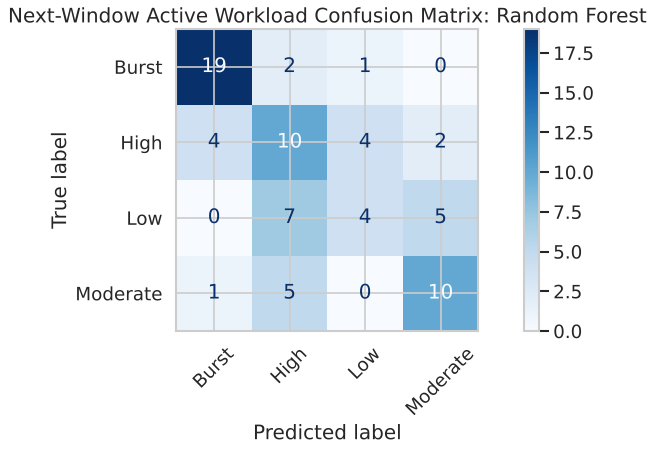

Next-window overload label distribution:


,count
label,
Not Overload,193
Overload,101


Chronological overload split: train=220, test=74
Overload split strategy: Chronological


,train_count,test_count
next_window_overload,,
Not Overload,161,32
Overload,59,42


,task,model,split_strategy,accuracy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
0,next_window_overload_prediction,Random Forest,Chronological,0.729730,0.706101,0.711538,0.880952,0.787234,0.745536,0.727793
1,next_window_overload_prediction,Persistence Baseline,Chronological,0.743243,0.732887,0.755556,0.809524,0.781609,0.732887,0.719748
2,next_window_overload_prediction,Gradient Boosting,Chronological,0.716216,0.709077,0.744186,0.761905,0.752941,0.716146,0.709478
3,next_window_overload_prediction,Logistic Regression,Chronological,0.621622,0.607143,0.652174,0.714286,0.681818,0.643973,0.688558



Classification report for Logistic Regression:
              precision    recall  f1-score   support

           0       0.57      0.50      0.53        32
           1       0.65      0.71      0.68        42

    accuracy                           0.62        74
   macro avg       0.61      0.61      0.61        74
weighted avg       0.62      0.62      0.62        74


Classification report for Random Forest:
              precision    recall  f1-score   support

           0       0.77      0.53      0.63        32
           1       0.71      0.88      0.79        42

    accuracy                           0.73        74
   macro avg       0.74      0.71      0.71        74
weighted avg       0.74      0.73      0.72        74


Classification report for Gradient Boosting:
              precision    recall  f1-score   support

           0       0.68      0.66      0.67        32
           1       0.74      0.76      0.75        42

    accuracy                           0.72   

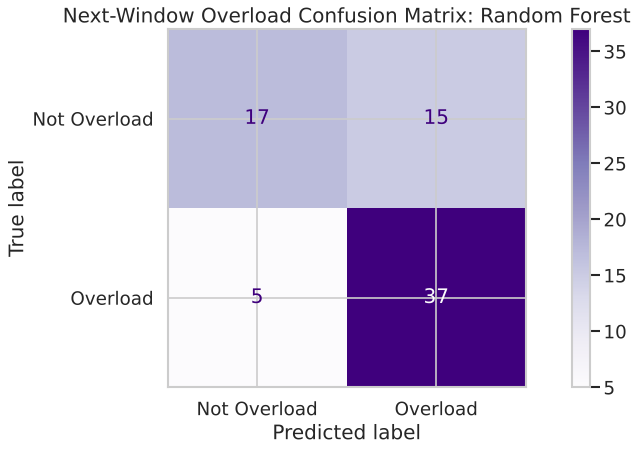

In [13]:
workload_model_features = [
    "alert_count",
    "alert_rate",
    "attack_diversity",
    "critical_alert_count",
    "high_severity_alert_count",
    "background_alert_count",
    "background_alert_ratio",
    "critical_label_diversity",
    "repeated_alert_ratio",
    "burst_score",
    "protocol_diversity",
    "destination_port_diversity",
    "unique_source_ip_count",
    "unique_destination_ip_count",
    "mental_demand_proxy",
    "temporal_demand_proxy",
    "effort_proxy",
    "frustration_proxy",
    "performance_pressure_proxy",
    "workload_score",
]

# Ensure 'next_alert_load_level' is present for workload prediction
comparison_df["next_alert_load_level"] = comparison_df["alert_load_level"].shift(-1)

# Use consecutive active windows only: the current window must also contain alerts.
workload_model_df = comparison_df.loc[
    comparison_df["alert_load_level"].isin(ACTIVE_LEVELS)
    & comparison_df["next_alert_load_level"].notna()
    & comparison_df["next_alert_load_level"].isin(ACTIVE_LEVELS)
].copy()
workload_model_df = workload_model_df.sort_values("window_start").reset_index(drop=True)

if len(workload_model_df) < 2:
    raise ValueError(
        "Not enough active next-window labels were produced to train and test the workload prediction models."
    )

X_workload = workload_model_df[workload_model_features]
y_workload = workload_model_df["next_alert_load_level"]

workload_class_counts = y_workload.value_counts().reindex(ACTIVE_LEVELS, fill_value=0)
print("Active next-window workload counts:")
display(workload_class_counts.rename_axis("level").to_frame("count"))

workload_label_encoder = LabelEncoder()
y_workload_encoded = workload_label_encoder.fit_transform(y_workload)
workload_labels = np.arange(len(workload_label_encoder.classes_))

split_index = max(int(len(workload_model_df) * 0.75), 1)
split_index = min(split_index, len(workload_model_df) - 1)

Xw_train = X_workload.iloc[:split_index]
Xw_test = X_workload.iloc[split_index:]
yw_train = y_workload_encoded[:split_index]
yw_test = y_workload_encoded[split_index:]
workload_split_strategy = "Chronological"

workload_stratify = choose_stratify_target(y_workload_encoded)
if needs_multiclass_rebalance(
    yw_train,
    yw_test,
    workload_labels,
    min_class_cases=MIN_WORKLOAD_CLASS_TEST_COUNT,
):
    if workload_stratify is not None:
        print(
            "Chronological workload split under-represented one or more active classes. "
            "Falling back to a stratified random split for the multiclass workload model."
        )
        Xw_train, Xw_test, yw_train, yw_test = train_test_split(
            X_workload,
            y_workload_encoded,
            test_size=0.25,
            random_state=SEED,
            stratify=workload_stratify,
        )
        workload_split_strategy = "Stratified random"
    else:
        print(
            "One or more active workload classes are still too rare for a balanced split. "
            "Multiclass workload results should be treated as exploratory."
        )
else:
    print(f"Chronological workload split: train={len(Xw_train):,}, test={len(Xw_test):,}")
    print(
        f"Train window range: {workload_model_df.iloc[0]['window_start']} -> "
        f"{workload_model_df.iloc[split_index - 1]['window_start']}"
    )
    print(
        f"Test window range: {workload_model_df.iloc[split_index]['window_start']} -> "
        f"{workload_model_df.iloc[-1]['window_start']}"
    )

train_workload_distribution = (
    pd.Series(yw_train)
    .value_counts()
    .reindex(workload_labels, fill_value=0)
    .rename(index=lambda idx: workload_label_encoder.classes_[idx])
    .rename_axis("level")
    .to_frame("train_count")
)
test_workload_distribution = (
    pd.Series(yw_test)
    .value_counts()
    .reindex(workload_labels, fill_value=0)
    .rename(index=lambda idx: workload_label_encoder.classes_[idx])
    .rename_axis("level")
    .to_frame("test_count")
)
print(f"Workload split strategy: {workload_split_strategy}")
display(train_workload_distribution.join(test_workload_distribution, how="outer").fillna(0).astype(int))

workload_models = make_model_dict(
    "multiclass",
    num_classes=len(workload_label_encoder.classes_),
)
if pd.Series(yw_train).nunique() < len(workload_label_encoder.classes_):
    workload_models.pop("XGBoost", None)

trained_workload_models = {}
workload_results_rows = []
workload_reports = {}

modal_workload_label = (
    pd.Series(workload_label_encoder.inverse_transform(yw_train)).mode().iloc[0]
)
workload_baseline_labels = workload_model_df.loc[Xw_test.index, "alert_load_level"].astype("string")
workload_baseline_labels = workload_baseline_labels.where(
    workload_baseline_labels.isin(ACTIVE_LEVELS),
    other=pd.NA,
).fillna(modal_workload_label)
workload_baseline_predictions = workload_label_encoder.transform(
    workload_baseline_labels.astype(str)
)

baseline_workload_report_dict = classification_report(
    yw_test,
    workload_baseline_predictions,
    labels=workload_labels,
    target_names=workload_label_encoder.classes_,
    output_dict=True,
    zero_division=0,
)
workload_results_rows.append(
    {
        "task": "next_active_window_workload_level_prediction",
        "model": "Persistence Baseline",
        "split_strategy": workload_split_strategy,
        "accuracy": accuracy_score(yw_test, workload_baseline_predictions),
        "balanced_accuracy": balanced_accuracy_score(yw_test, workload_baseline_predictions),
        "macro_f1": baseline_workload_report_dict["macro avg"]["f1-score"],
        "weighted_f1": baseline_workload_report_dict["weighted avg"]["f1-score"],
    }
)

for model_name, model in workload_models.items():
    model.fit(Xw_train, yw_train)
    workload_predictions = model.predict(Xw_test)
    trained_workload_models[model_name] = model

    workload_report_text = classification_report(
        yw_test,
        workload_predictions,
        labels=workload_labels,
        target_names=workload_label_encoder.classes_,
        zero_division=0,
    )
    workload_report_dict = classification_report(
        yw_test,
        workload_predictions,
        labels=workload_labels,
        target_names=workload_label_encoder.classes_,
        output_dict=True,
        zero_division=0,
    )
    workload_reports[model_name] = workload_report_text

    workload_results_rows.append(
        {
            "task": "next_active_window_workload_level_prediction",
            "model": model_name,
            "split_strategy": workload_split_strategy,
            "accuracy": accuracy_score(yw_test, workload_predictions),
            "balanced_accuracy": balanced_accuracy_score(yw_test, workload_predictions),
            "macro_f1": workload_report_dict["macro avg"]["f1-score"],
            "weighted_f1": workload_report_dict["weighted avg"]["f1-score"],
        }
    )

workload_results = pd.DataFrame(workload_results_rows).sort_values(
    ["macro_f1", "balanced_accuracy", "accuracy"], ascending=False
).reset_index(drop=True)

display(workload_results)

for model_name, report_text in workload_reports.items():
    print(f"\nClassification report for {model_name}:")
    print(report_text)

learned_workload_results = workload_results.loc[
    workload_results["model"] != "Persistence Baseline"
].reset_index(drop=True)
best_workload_model_name = learned_workload_results.iloc[0]["model"]
best_workload_model = trained_workload_models[best_workload_model_name]
best_workload_predictions = best_workload_model.predict(Xw_test)

plt.figure(figsize=(8, 6))
ConfusionMatrixDisplay.from_predictions(
    yw_test,
    best_workload_predictions,
    labels=workload_labels,
    display_labels=workload_label_encoder.classes_,
    cmap="Blues",
    xticks_rotation=45,
)
plt.title(f"Next-Window Active Workload Confusion Matrix: {best_workload_model_name}")
save_current_figure("workload_confusion_matrix.png")
plt.show()

overload_model_features = workload_model_features.copy()
overload_model_df = workload_model_df.copy()
overload_model_df["next_window_overload"] = (
    overload_model_df["next_alert_load_level"].isin(OVERLOAD_LEVELS)
).astype(int)

print("Next-window overload label distribution:")
display(
    overload_model_df["next_window_overload"]
    .value_counts()
    .rename(index={0: "Not Overload", 1: "Overload"})
    .rename_axis("label")
    .to_frame("count")
)

overload_results = pd.DataFrame()
trained_overload_models = {}
overload_reports = {}
best_overload_model_name = None
best_overload_model = None
best_overload_predictions = None
Xo_test = None
yo_test = None

if overload_model_df["next_window_overload"].nunique() < 2:
    print(
        "Next-window overload target has only one class in this run. "
        "Use a smaller window size or stronger burst injection if you want a harder overload task."
    )
else:
    X_overload = overload_model_df[overload_model_features]
    y_overload = overload_model_df["next_window_overload"].astype(int)

    split_index = max(int(len(overload_model_df) * 0.75), 1)
    split_index = min(split_index, len(overload_model_df) - 1)

    Xo_train = X_overload.iloc[:split_index]
    Xo_test = X_overload.iloc[split_index:]
    yo_train = y_overload.iloc[:split_index]
    yo_test = y_overload.iloc[split_index:]
    overload_split_strategy = "Chronological"

    overload_stratify = choose_stratify_target(y_overload)
    if needs_binary_rebalance(
        yo_train,
        yo_test,
        min_positive_cases=MIN_BINARY_TEST_POSITIVES,
    ):
        if overload_stratify is not None:
            print(
                "Chronological overload split under-represented positive windows. "
                "Falling back to a stratified random split for the overload model."
            )
            Xo_train, Xo_test, yo_train, yo_test = train_test_split(
                X_overload,
                y_overload,
                test_size=0.25,
                random_state=SEED,
                stratify=overload_stratify,
            )
            overload_split_strategy = "Stratified random"
        else:
            print(
                "Overload target classes are still too rare for a balanced split. "
                "Binary overload results should be treated as exploratory."
            )
    else:
        print(f"Chronological overload split: train={len(Xo_train):,}, test={len(Xo_test):,}")

    print(f"Overload split strategy: {overload_split_strategy}")
    display(
        pd.DataFrame(
            {
                "train_count": yo_train.value_counts().sort_index(),
                "test_count": yo_test.value_counts().sort_index(),
            }
        )
        .rename(index={0: "Not Overload", 1: "Overload"})
        .fillna(0)
        .astype(int)
    )

    if yo_train.nunique() < 2 or yo_test.nunique() < 2:
        print(
            "Overload split still contains only one class after fallback. "
            "Skipping overload model fitting for this run."
        )
    else:
        overload_rows = []
        overload_baseline_predictions = (
            overload_model_df.loc[Xo_test.index, "alert_load_level"]
            .isin(OVERLOAD_LEVELS)
            .astype(int)
            .to_numpy()
        )
        overload_baseline_scores = overload_baseline_predictions.astype(float)
        overload_rows.append(
            {
                "task": "next_window_overload_prediction",
                "model": "Persistence Baseline",
                "split_strategy": overload_split_strategy,
                "accuracy": accuracy_score(yo_test, overload_baseline_predictions),
                "balanced_accuracy": balanced_accuracy_score(yo_test, overload_baseline_predictions),
                "precision": precision_score(yo_test, overload_baseline_predictions, zero_division=0),
                "recall": recall_score(yo_test, overload_baseline_predictions, zero_division=0),
                "f1": f1_score(yo_test, overload_baseline_predictions, zero_division=0),
                "roc_auc": safe_binary_roc_auc(yo_test, overload_baseline_scores),
                "average_precision": safe_binary_average_precision(yo_test, overload_baseline_scores),
            }
        )

        overload_models = make_model_dict("binary")
        for model_name, model in overload_models.items():
            model.fit(Xo_train, yo_train)
            overload_predictions = model.predict(Xo_test)
            overload_scores = get_positive_scores(model, Xo_test)
            trained_overload_models[model_name] = model
            overload_reports[model_name] = classification_report(
                yo_test,
                overload_predictions,
                zero_division=0,
            )

            overload_rows.append(
                {
                    "task": "next_window_overload_prediction",
                    "model": model_name,
                    "split_strategy": overload_split_strategy,
                    "accuracy": accuracy_score(yo_test, overload_predictions),
                    "balanced_accuracy": balanced_accuracy_score(yo_test, overload_predictions),
                    "precision": precision_score(yo_test, overload_predictions, zero_division=0),
                    "recall": recall_score(yo_test, overload_predictions, zero_division=0),
                    "f1": f1_score(yo_test, overload_predictions, zero_division=0),
                    "roc_auc": safe_binary_roc_auc(yo_test, overload_scores),
                    "average_precision": safe_binary_average_precision(yo_test, overload_scores),
                }
            )

        overload_results = pd.DataFrame(overload_rows).sort_values(
            ["average_precision", "f1", "balanced_accuracy", "accuracy"],
            ascending=False,
        ).reset_index(drop=True)
        display(overload_results)

        for model_name, report_text in overload_reports.items():
            print(f"\nClassification report for {model_name}:")
            print(report_text)

        learned_overload_results = overload_results.loc[
            overload_results["model"] != "Persistence Baseline"
        ].reset_index(drop=True)
if trained_overload_models and Xo_test is not None and yo_test is not None:
    best_overload_model_name = learned_overload_results.iloc[0]["model"]
    best_overload_model = trained_overload_models[best_overload_model_name]
    best_overload_predictions = best_overload_model.predict(Xo_test)

    plt.figure(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        yo_test,
        best_overload_predictions,
        display_labels=["Not Overload", "Overload"],
        cmap="Purples",
    )
    plt.title(f"Next-Window Overload Confusion Matrix: {best_overload_model_name}")
    save_current_figure("overload_confusion_matrix.png")
    plt.show()
else:
    print("Overload evaluation was skipped because a valid two-class holdout was unavailable.")


## 13. Machine Learning: Next-Window Missed-Risk Prediction

The binary target is the next window's `baseline_missed_risk`. Current-window alert-stream features are used; workload and pressure proxies derived from the target are excluded. Results are withheld when the chronological holdout lacks both classes.


In [14]:
# Prospective, leakage-controlled missed-risk experiment. Current-window signals
# predict the next window's baseline missed-risk label; target-derived workload
# and pressure proxies are deliberately excluded.
risk_model_features = [
    "alert_count", "attack_diversity", "critical_alert_count", "mean_severity",
    "max_severity", "alert_rate", "burst_score", "repeated_alert_ratio",
    "protocol_diversity", "destination_port_diversity", "unique_source_ip_count",
    "unique_destination_ip_count",
]
forbidden = {"workload_score", "mental_demand_proxy", "temporal_demand_proxy",
             "effort_proxy", "frustration_proxy", "performance_pressure_proxy",
             "baseline_missed_risk", "adaptive_missed_risk"}
assert not (set(risk_model_features) & forbidden), "Leakage guard failed."
risk_model_df = comparison_df.sort_values("window_start").copy()
risk_model_df["next_window_baseline_missed_risk"] = risk_model_df["baseline_missed_risk"].shift(-1)
risk_model_df = risk_model_df.loc[
    risk_model_df["alert_load_level"].isin(ACTIVE_LEVELS)
    & risk_model_df["next_alert_load_level"].isin(ACTIVE_LEVELS)
    & risk_model_df["next_window_baseline_missed_risk"].notna()
].reset_index(drop=True)
X_risk = risk_model_df[risk_model_features]
y_risk = risk_model_df["next_window_baseline_missed_risk"].astype(int)
split = min(max(int(len(risk_model_df) * 0.75), 1), len(risk_model_df) - 1)
Xr_train, Xr_test = X_risk.iloc[:split], X_risk.iloc[split:]
yr_train, yr_test = y_risk.iloc[:split], y_risk.iloc[split:]
risk_result_columns = [
    "task", "model", "split_strategy", "balanced_accuracy", "precision",
    "recall", "f1", "roc_auc", "average_precision",
]
risk_results, trained_risk_models, risk_reports = pd.DataFrame(columns=risk_result_columns), {}, {}
best_risk_model_name = best_risk_model = best_risk_predictions = best_risk_scores = None
print("Leakage guard passed. Prospective chronological next-window risk evaluation:")
display(pd.DataFrame({"train_count": yr_train.value_counts(), "test_count": yr_test.value_counts()})
    .reindex([0, 1], fill_value=0).rename(index={0: "No Risk", 1: "Missed Risk"}))
if yr_train.nunique() < 2 or yr_test.nunique() < 2:
    print("Holdout lacks both classes; performance is intentionally not reported.")
else:
    persistence_pred = risk_model_df["baseline_missed_risk"].iloc[split:].astype(int).to_numpy()
    rows = [{"task": "next_window_missed_risk", "model": "Persistence Baseline",
        "split_strategy": "Chronological", "balanced_accuracy": balanced_accuracy_score(yr_test, persistence_pred),
        "precision": precision_score(yr_test, persistence_pred, zero_division=0),
        "recall": recall_score(yr_test, persistence_pred, zero_division=0), "f1": f1_score(yr_test, persistence_pred, zero_division=0),
        "roc_auc": safe_binary_roc_auc(yr_test, persistence_pred.astype(float)),
        "average_precision": safe_binary_average_precision(yr_test, persistence_pred.astype(float))}]
    for name, model in make_model_dict("binary").items():
        model.fit(Xr_train, yr_train)
        pred, score = model.predict(Xr_test), get_positive_scores(model, Xr_test)
        trained_risk_models[name] = model
        rows.append({"task": "next_window_missed_risk", "model": name,
            "split_strategy": "Chronological", "balanced_accuracy": balanced_accuracy_score(yr_test, pred),
            "precision": precision_score(yr_test, pred, zero_division=0),
            "recall": recall_score(yr_test, pred, zero_division=0), "f1": f1_score(yr_test, pred, zero_division=0),
            "roc_auc": safe_binary_roc_auc(yr_test, score), "average_precision": safe_binary_average_precision(yr_test, score)})
    risk_results = pd.DataFrame(rows).sort_values(["average_precision", "f1"], ascending=False)
    display(risk_results)


Leakage guard passed. Prospective chronological next-window risk evaluation:


,train_count,test_count
next_window_baseline_missed_risk,,
No Risk,200,58
Missed Risk,20,16


,task,model,split_strategy,balanced_accuracy,precision,recall,f1,roc_auc,average_precision
2,next_window_missed_risk,Random Forest,Chronological,0.896552,0.571429,1.0000,0.727273,0.971983,0.860891
0,next_window_missed_risk,Persistence Baseline,Chronological,0.880388,0.812500,0.8125,0.812500,0.880388,0.700697
3,next_window_missed_risk,Gradient Boosting,Chronological,0.576509,0.600000,0.1875,0.285714,0.904095,0.644205
1,next_window_missed_risk,Logistic Regression,Chronological,0.639009,0.714286,0.3125,0.434783,0.714440,0.512322


## 14. Explainability

For a tree-based model such as Random Forest or XGBoost, feature importance can highlight which workload dimensions contribute most to:
- workload-level prediction
- missed-critical-alert risk prediction

SHAP is intentionally omitted here to keep the notebook lighter and more beginner-friendly for Colab CPU execution.


Saved figure: exported_results/workload_feature_importance.png


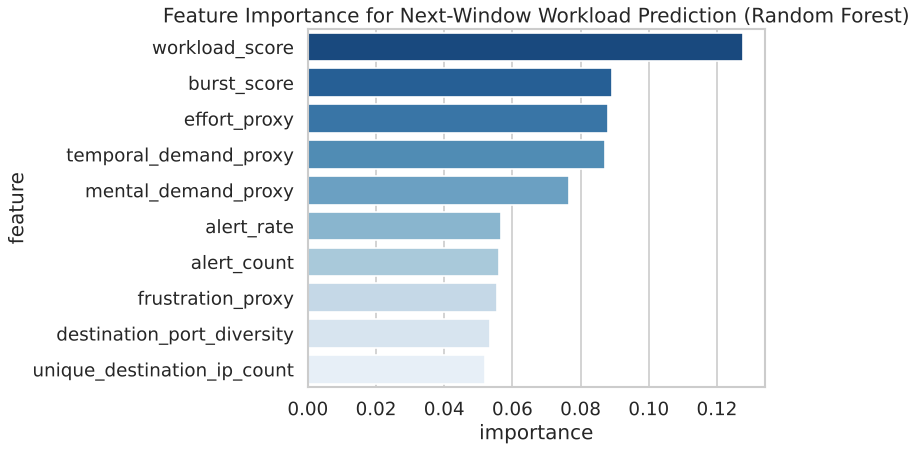

,feature,importance
19,workload_score,0.127610
9,burst_score,0.089171
16,effort_proxy,0.088097
15,temporal_demand_proxy,0.087216
14,mental_demand_proxy,0.076588
1,alert_rate,0.056718
0,alert_count,0.055934
17,frustration_proxy,0.055513
11,destination_port_diversity,0.053541
13,unique_destination_ip_count,0.052099


Interpretation: Higher-ranked features contribute more strongly to predicting the next window's workload state.
Saved figure: exported_results/overload_feature_importance.png


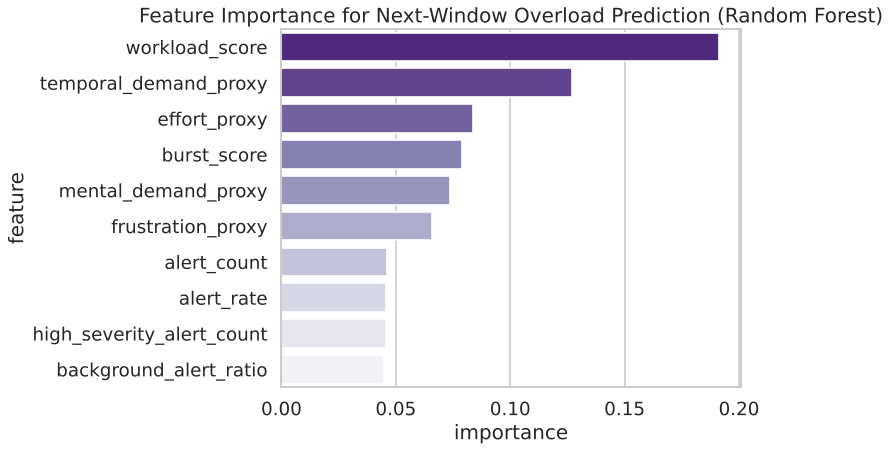

,feature,importance
19,workload_score,0.191166
15,temporal_demand_proxy,0.127119
16,effort_proxy,0.083612
9,burst_score,0.078990
14,mental_demand_proxy,0.073842
17,frustration_proxy,0.065666
0,alert_count,0.046071
1,alert_rate,0.045638
4,high_severity_alert_count,0.045568
6,background_alert_ratio,0.044953


Saved figure: exported_results/missed_risk_feature_importance.png


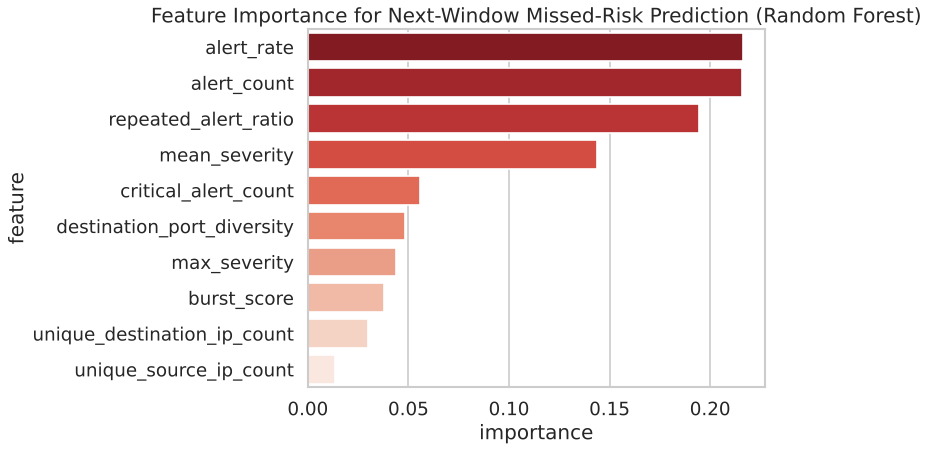

,feature,importance
5,alert_rate,0.216271
0,alert_count,0.215985
7,repeated_alert_ratio,0.194484
3,mean_severity,0.143600
2,critical_alert_count,0.055870
9,destination_port_diversity,0.048131
4,max_severity,0.043876
6,burst_score,0.038006
11,unique_destination_ip_count,0.029957
10,unique_source_ip_count,0.013667


Interpretation: Features near the top are the strongest contributors to predicting whether critical alerts are likely to be buried in the next window.


In [15]:
def extract_feature_importance(model, feature_names):
    if hasattr(model, "named_steps"):
        final_estimator = model.named_steps.get("model", None)
    else:
        final_estimator = model

    if final_estimator is None or not hasattr(final_estimator, "feature_importances_"):
        return None

    importance_df = pd.DataFrame(
        {
            "feature": feature_names,
            "importance": final_estimator.feature_importances_,
        }
    ).sort_values("importance", ascending=False)
    return importance_df

workload_importance_model_name = None
workload_importance_df = None
for candidate_name in [best_workload_model_name, "XGBoost", "Random Forest"]:
    candidate_model = trained_workload_models.get(candidate_name)
    if candidate_model is None:
        continue
    candidate_importance = extract_feature_importance(candidate_model, workload_model_features)
    if candidate_importance is not None:
        workload_importance_model_name = candidate_name
        workload_importance_df = candidate_importance
        break

if workload_importance_df is not None:
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=workload_importance_df.head(10),
        x="importance",
        y="feature",
        palette="Blues_r",
    )
    plt.title(
        f"Feature Importance for Next-Window Workload Prediction ({workload_importance_model_name})"
    )
    save_current_figure("workload_feature_importance.png")
    plt.show()
    display(workload_importance_df.head(10))
    print(
        "Interpretation: Higher-ranked features contribute more strongly to predicting "
        "the next window's workload state."
    )
else:
    print("No tree-based feature importance was available for the workload model selection.")

overload_importance_model_name = None
overload_importance_df = None
if "trained_overload_models" in globals() and trained_overload_models:
    for candidate_name in [best_overload_model_name, "XGBoost", "Random Forest"]:
        candidate_model = trained_overload_models.get(candidate_name)
        if candidate_model is None:
            continue
        candidate_importance = extract_feature_importance(candidate_model, overload_model_features)
        if candidate_importance is not None:
            overload_importance_model_name = candidate_name
            overload_importance_df = candidate_importance
            break

if overload_importance_df is not None:
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=overload_importance_df.head(10),
        x="importance",
        y="feature",
        palette="Purples_r",
    )
    plt.title(
        f"Feature Importance for Next-Window Overload Prediction ({overload_importance_model_name})"
    )
    save_current_figure("overload_feature_importance.png")
    plt.show()
    display(overload_importance_df.head(10))

risk_importance_model_name = None
risk_importance_df = None
for candidate_name in [best_risk_model_name, "XGBoost", "Random Forest"]:
    candidate_model = trained_risk_models.get(candidate_name) if trained_risk_models else None
    if candidate_model is None:
        continue
    candidate_importance = extract_feature_importance(candidate_model, risk_model_features)
    if candidate_importance is not None:
        risk_importance_model_name = candidate_name
        risk_importance_df = candidate_importance
        break

if risk_importance_df is not None:
    plt.figure(figsize=(10, 6))
    sns.barplot(
        data=risk_importance_df.head(10),
        x="importance",
        y="feature",
        palette="Reds_r",
    )
    plt.title(
        f"Feature Importance for Next-Window Missed-Risk Prediction ({risk_importance_model_name})"
    )
    save_current_figure("missed_risk_feature_importance.png")
    plt.show()
    display(risk_importance_df.head(10))
    print(
        "Interpretation: Features near the top are the strongest contributors to predicting "
        "whether critical alerts are likely to be buried in the next window."
    )
elif y_risk.nunique() >= 2:
    print("No tree-based feature importance was available for the missed-risk model selection.")


## 15. Baseline vs Adaptive Comparison

This section compares how the static baseline and adaptive SOC workflows behave across alert-load conditions.


In [16]:
# Compute reduction from aggregate counts, which is bounded and reproducible.
alert_level_order = ["Idle", "Low", "Moderate", "High", "Burst"]
baseline_vs_adaptive_summary = comparison_df.groupby("alert_load_level", dropna=False).agg(
    windows=("window_start", "count"), total_baseline_alerts=("baseline_total_alerts_shown", "sum"),
    total_adaptive_display_items=("adaptive_grouped_alert_count", "sum"),
    avg_baseline_first_critical_rank=("baseline_first_critical_rank", "mean"),
    avg_adaptive_first_critical_rank=("adaptive_first_critical_rank", "mean"),
    baseline_missed_risk_rate=("baseline_missed_risk", "mean"),
    adaptive_missed_risk_rate=("adaptive_missed_risk", "mean"),
).reset_index()
baseline_vs_adaptive_summary["alert_reduction_rate"] = 1 - (
    baseline_vs_adaptive_summary["total_adaptive_display_items"] /
    baseline_vs_adaptive_summary["total_baseline_alerts"].clip(lower=1))
assert baseline_vs_adaptive_summary["alert_reduction_rate"].between(0, 1).all()
baseline_vs_adaptive_summary["alert_load_level"] = pd.Categorical(
    baseline_vs_adaptive_summary["alert_load_level"], categories=alert_level_order, ordered=True)
active_baseline_vs_adaptive_summary = baseline_vs_adaptive_summary.query("alert_load_level in @ACTIVE_LEVELS")
total_baseline = comparison_df["baseline_total_alerts_shown"].sum()
total_adaptive = comparison_df["adaptive_grouped_alert_count"].sum()
overall_comparison = pd.DataFrame({"metric": ["Total baseline alerts", "Total adaptive display items", "Overall alert reduction"],
    "value": [total_baseline, total_adaptive, 1 - total_adaptive / max(total_baseline, 1)]})
print("Validated simulation summary:")
display(active_baseline_vs_adaptive_summary)
display(overall_comparison)
# Visibility outcomes conditional on windows that contain simulated critical alerts.
critical_windows_df = comparison_df.loc[
    comparison_df["alert_load_level"].isin(ACTIVE_LEVELS) & (comparison_df["critical_alert_count"] > 0)
]
critical_window_summary = critical_windows_df.groupby("alert_load_level").agg(
    all_windows=("window_start", "size"),
    critical_alerts=("critical_alert_count", "sum"),
    baseline_missed=("baseline_missed_risk", "sum"),
    adaptive_group_budget_missed=("adaptive_missed_risk", "sum"),
    adaptive_alert_budget_missed=("adaptive_instance_missed_risk", "sum"),
    baseline_first_rank=("baseline_first_critical_rank", "mean"),
    adaptive_group_first_rank=("adaptive_first_critical_rank", "mean"),
    adaptive_alert_first_rank=("adaptive_instance_first_critical_rank", "mean"),
    baseline_coverage=("baseline_critical_instance_coverage", "mean"),
    adaptive_group_budget_coverage=("adaptive_critical_instance_coverage", "mean"),
    adaptive_alert_budget_coverage=("adaptive_instance_critical_coverage", "mean"),
    mean_display_items=("adaptive_grouped_alert_count", "mean"),
    max_display_items=("adaptive_grouped_alert_count", "max"),
    mean_review_budget=("baseline_review_budget", "mean"),
).rename(columns={"all_windows": "critical_windows"}).reindex(ACTIVE_LEVELS).reset_index()
for prefix in ["baseline", "adaptive_group_budget", "adaptive_alert_budget"]:
    critical_window_summary[f"{prefix}_missed_rate"] = (
        critical_window_summary[f"{prefix}_missed"] / critical_window_summary["critical_windows"]
    )
print("Visibility outcomes in windows containing simulated critical alerts:")
display(critical_window_summary)


Validated simulation summary:


,alert_load_level,windows,total_baseline_alerts,total_adaptive_display_items,avg_baseline_first_critical_rank,avg_adaptive_first_critical_rank,baseline_missed_risk_rate,adaptive_missed_risk_rate,alert_reduction_rate
0,Burst,57,11938,161,32.840909,1.0,0.614035,0.0,0.986514
1,High,114,1760,234,10.000000,1.0,0.017544,0.0,0.867045
3,Low,228,562,562,NaN,NaN,0.000000,0.0,0.000000
4,Moderate,168,1970,1970,6.000000,3.0,0.000000,0.0,0.000000


,metric,value
0,Total baseline alerts,16230.000000
1,Total adaptive display items,2927.000000
2,Overall alert reduction,0.819655


Visibility outcomes in windows containing simulated critical alerts:


,alert_load_level,critical_windows,critical_alerts,baseline_missed,adaptive_group_budget_missed,adaptive_alert_budget_missed,baseline_first_rank,adaptive_group_first_rank,adaptive_alert_first_rank,baseline_coverage,adaptive_group_budget_coverage,adaptive_alert_budget_coverage,mean_display_items,max_display_items,mean_review_budget,baseline_missed_rate,adaptive_group_budget_missed_rate,adaptive_alert_budget_missed_rate
0,Low,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Moderate,1.0,1.0,0.0,0.0,0.0,6.000000,3.0,3.000000,1.000000,1.0,1.000000,9.000000,9.0,9.000000,0.000000,0.0,0.000000
2,High,12.0,15.0,2.0,0.0,0.0,10.000000,1.0,5.333333,0.777778,1.0,0.944444,2.083333,3.0,15.500000,0.166667,0.0,0.000000
3,Burst,44.0,224.0,35.0,0.0,31.0,32.840909,1.0,29.750000,0.133348,1.0,0.186604,2.886364,3.0,9.977273,0.795455,0.0,0.704545


## 16. Visualization

The following plots provide a compact visual summary of alert pressure, workload trends, attack distribution, and baseline-versus-adaptive behavior.


Saved figure: exported_results/alert_volume_over_time.png


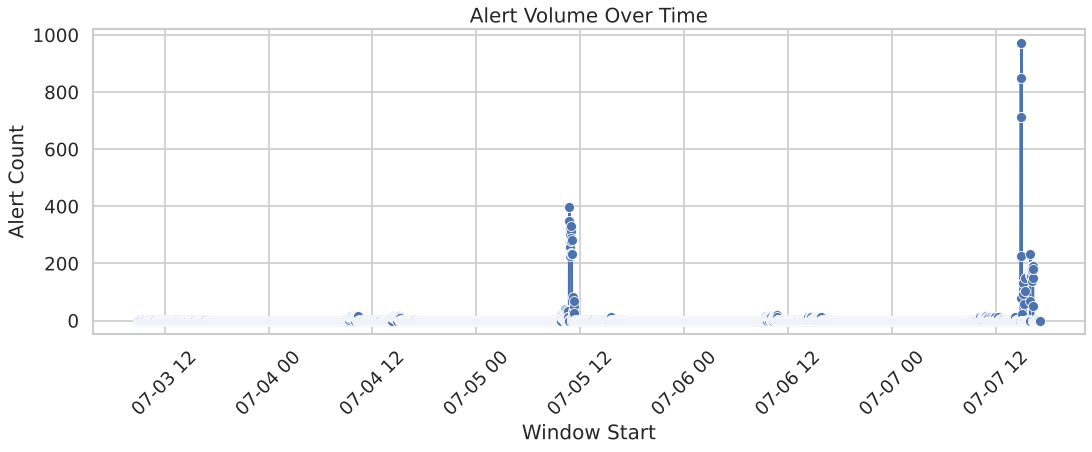

Saved figure: exported_results/workload_score_over_time.png


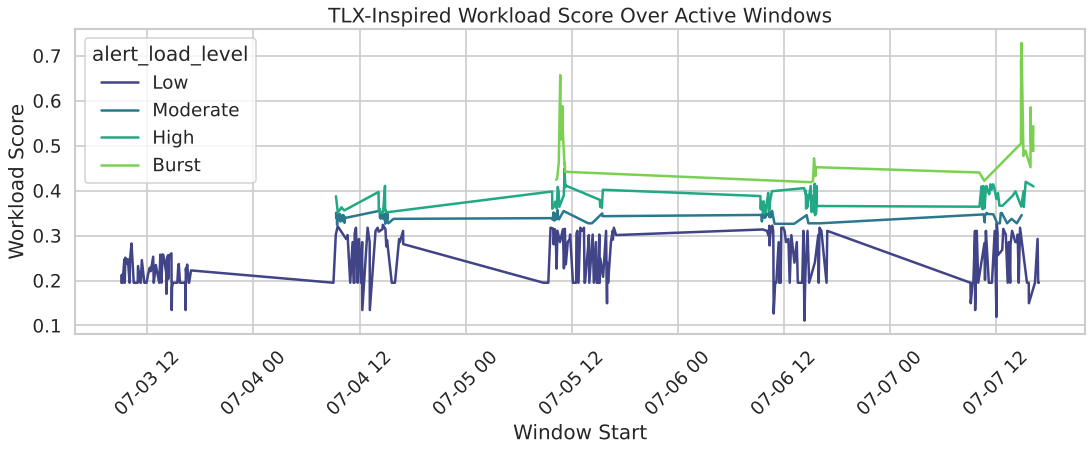

Saved figure: exported_results/alert_load_level_distribution.png


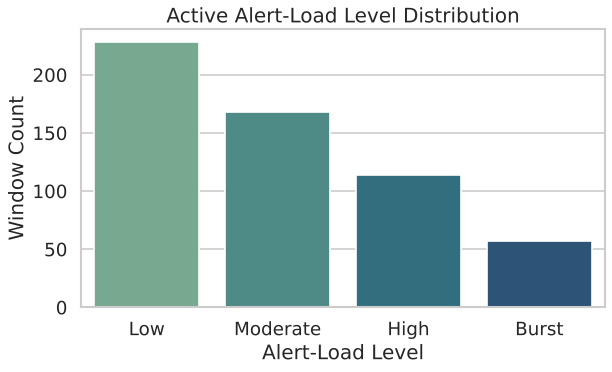

Saved figure: exported_results/attack_type_distribution.png


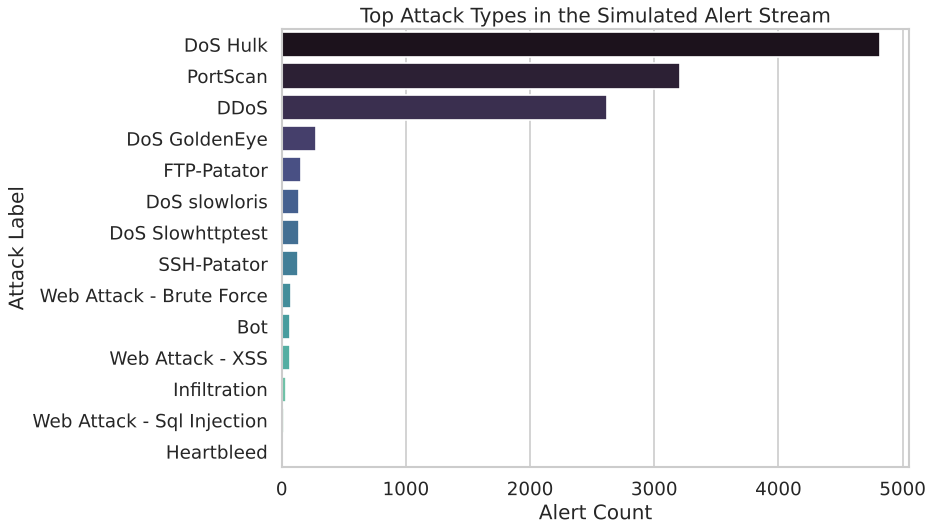

Saved figure: exported_results/baseline_vs_adaptive_alert_count.png


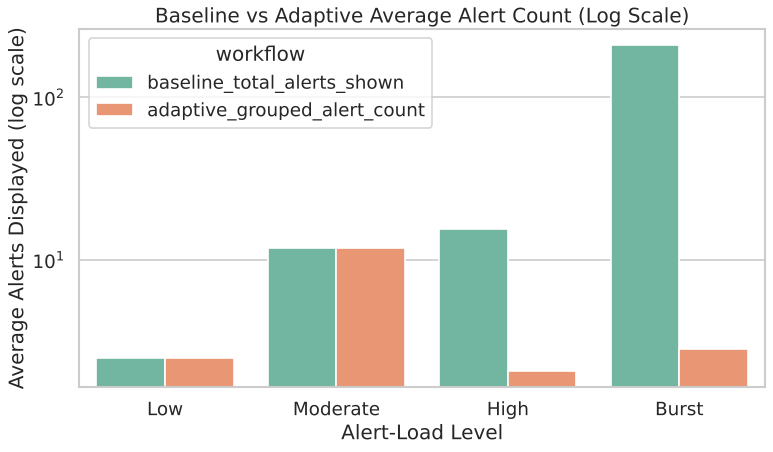

Saved figure: exported_results/critical_visibility_improvement.png


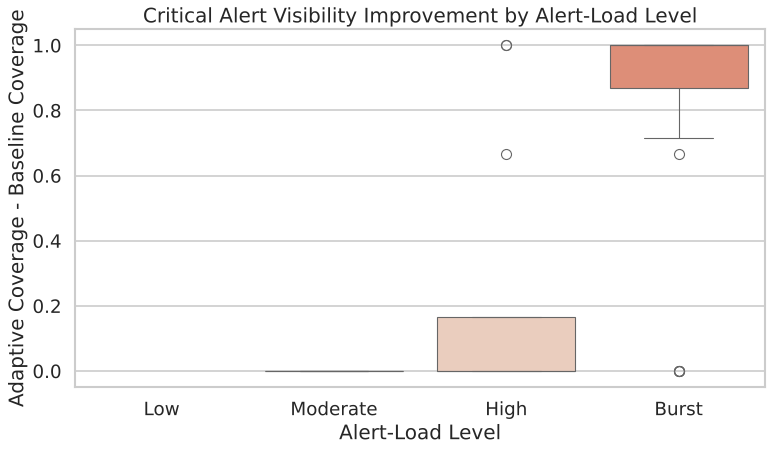

Saved figure: exported_results/workload_by_alert_load_level.png


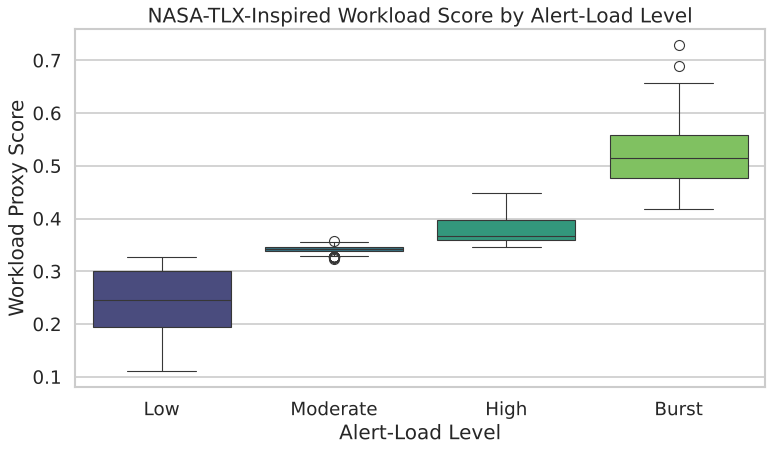

Saved figure: exported_results/alert_reduction_rate_by_level.png


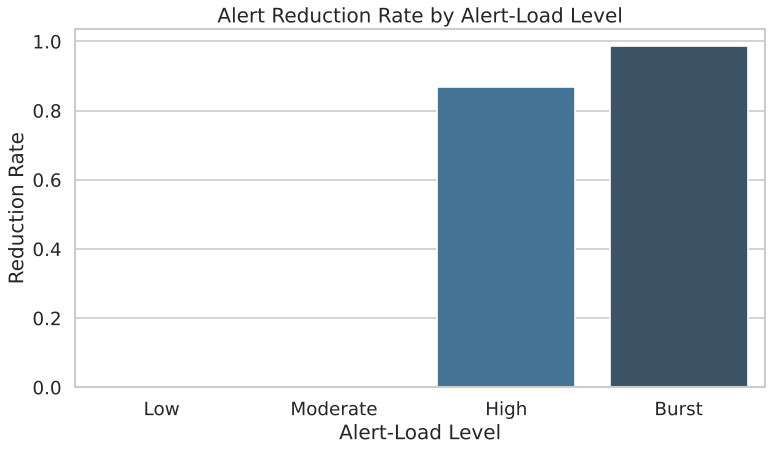

Saved figure: exported_results/baseline_vs_adaptive_critical_rank_critical_only.png


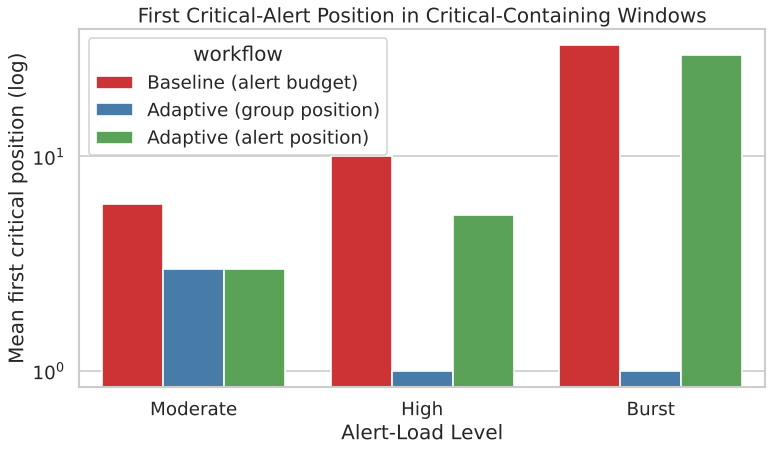

Saved figure: exported_results/baseline_vs_adaptive_missed_risk.png


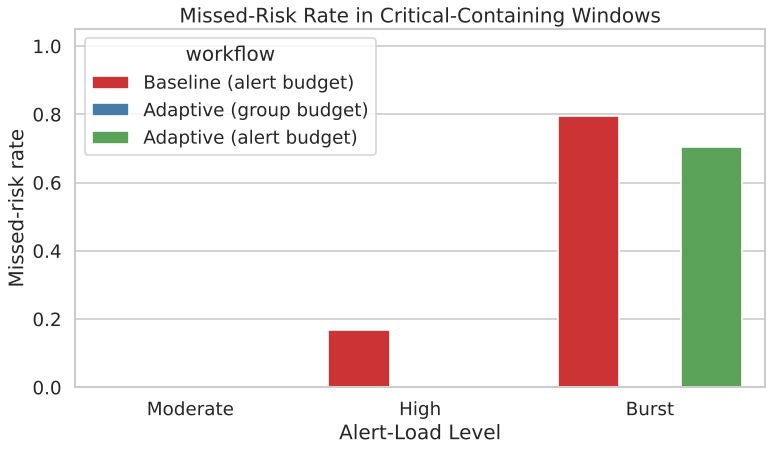

Saved figure: exported_results/alert_volume_by_day.png


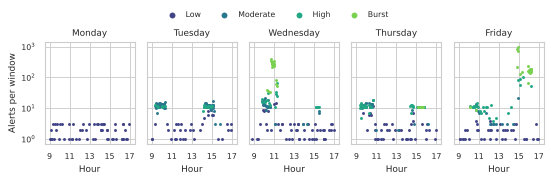

In [17]:
# Alert volume over time.
alert_level_order = ["Idle", "Low", "Moderate", "High", "Burst"]
active_comparison_df = comparison_df.loc[
    comparison_df["alert_load_level"].isin(ACTIVE_LEVELS)
].copy()

plt.figure(figsize=(14, 6))
sns.lineplot(data=comparison_df, x="window_start", y="alert_count", marker="o")
plt.title("Alert Volume Over Time")
plt.xlabel("Window Start")
plt.ylabel("Alert Count")
plt.xticks(rotation=45)
save_current_figure("alert_volume_over_time.png")
plt.show()

# TLX-inspired workload score over active windows.
plt.figure(figsize=(14, 6))
sns.lineplot(
    data=active_comparison_df,
    x="window_start",
    y="workload_score",
    hue="alert_load_level",
    hue_order=ACTIVE_LEVELS,
    palette="viridis",
)
plt.title("TLX-Inspired Workload Score Over Active Windows")
plt.xlabel("Window Start")
plt.ylabel("Workload Score")
plt.xticks(rotation=45)
save_current_figure("workload_score_over_time.png")
plt.show()

# Active alert-load level distribution.
plt.figure(figsize=(8, 5))
sns.countplot(
    data=active_comparison_df,
    x="alert_load_level",
    order=ACTIVE_LEVELS,
    palette="crest",
)
plt.title("Active Alert-Load Level Distribution")
plt.xlabel("Alert-Load Level")
plt.ylabel("Window Count")
save_current_figure("alert_load_level_distribution.png")
plt.show()

# Attack type distribution excluding synthetic benign background alerts.
attack_label_series = (
    alerts_df.loc[alerts_df["alert_origin"].astype("string") != "background_benign", "standard_label"]
    .astype("string")
    .dropna()
)
attack_label_series = attack_label_series.loc[attack_label_series != BACKGROUND_ALERT_LABEL]
top_attacks = (
    attack_label_series
    .value_counts()
    .head(15)
    .rename_axis("attack_label")
    .reset_index(name="count")
)
plt.figure(figsize=(12, 7))
sns.barplot(data=top_attacks, x="count", y="attack_label", palette="mako")
plt.title("Top Attack Types in the Simulated Alert Stream")
plt.xlabel("Alert Count")
plt.ylabel("Attack Label")
save_current_figure("attack_type_distribution.png")
plt.show()

# Baseline vs adaptive alert count for active windows.
plot_compare = active_comparison_df.groupby("alert_load_level", dropna=False)[
    ["baseline_total_alerts_shown", "adaptive_grouped_alert_count"]
].mean().reset_index()
plot_compare = plot_compare.melt(
    id_vars="alert_load_level",
    var_name="workflow",
    value_name="avg_alert_count",
)

plt.figure(figsize=(10, 6))
sns.barplot(
    data=plot_compare,
    x="alert_load_level",
    y="avg_alert_count",
    hue="workflow",
    order=ACTIVE_LEVELS,
    palette="Set2",
)
plt.yscale("log")
plt.title("Baseline vs Adaptive Average Alert Count (Log Scale)")
plt.xlabel("Alert-Load Level")
plt.ylabel("Average Alerts Displayed (log scale)")
save_current_figure("baseline_vs_adaptive_alert_count.png")
plt.show()

# Critical coverage improvement across active critical-alert windows.
coverage_plot_df = comparison_df.loc[
    (comparison_df["critical_alert_count"] > 0)
    & comparison_df["alert_load_level"].isin(ACTIVE_LEVELS)
].copy()
if coverage_plot_df.empty:
    print("No critical-alert windows were available for the critical coverage plot.")
else:
    plt.figure(figsize=(10, 6))
    sns.boxplot(
        data=coverage_plot_df,
        x="alert_load_level",
        y="critical_coverage_improvement",
        order=ACTIVE_LEVELS,
        palette="coolwarm",
    )
    plt.title("Critical Alert Visibility Improvement by Alert-Load Level")
    plt.xlabel("Alert-Load Level")
    plt.ylabel("Adaptive Coverage - Baseline Coverage")
    save_current_figure("critical_visibility_improvement.png")
    plt.show()

# NASA-TLX-inspired workload comparison by alert-load level.
plt.figure(figsize=(10, 6))
sns.boxplot(data=active_comparison_df, x="alert_load_level", y="workload_score", order=ACTIVE_LEVELS, palette="viridis")
plt.title("NASA-TLX-Inspired Workload Score by Alert-Load Level")
plt.xlabel("Alert-Load Level"); plt.ylabel("Workload Proxy Score")
save_current_figure("workload_by_alert_load_level.png")
plt.show()

# Alert reduction and first-critical-rank improvements.
plt.figure(figsize=(10, 6))
sns.barplot(data=active_baseline_vs_adaptive_summary, x="alert_load_level", y="alert_reduction_rate", order=ACTIVE_LEVELS, palette="Blues_d")
plt.title("Alert Reduction Rate by Alert-Load Level")
plt.xlabel("Alert-Load Level"); plt.ylabel("Reduction Rate")
save_current_figure("alert_reduction_rate_by_level.png")
plt.show()

# First-critical rank and missed-risk in windows that contain simulated critical alerts.
workflow_names = {
    "baseline": "Baseline (alert budget)",
    "adaptive_group_budget": "Adaptive (group budget)",
    "adaptive_alert_budget": "Adaptive (alert budget)",
}
critical_levels = [level for level in ACTIVE_LEVELS
                   if level in set(critical_window_summary.dropna(subset=["critical_windows"])["alert_load_level"])]
rank_plot = critical_window_summary.melt(
    id_vars="alert_load_level",
    value_vars=["baseline_first_rank", "adaptive_group_first_rank", "adaptive_alert_first_rank"],
    var_name="workflow", value_name="mean_first_critical_rank",
)
rank_plot["workflow"] = rank_plot["workflow"].map({
    "baseline_first_rank": workflow_names["baseline"],
    "adaptive_group_first_rank": "Adaptive (group position)",
    "adaptive_alert_first_rank": "Adaptive (alert position)",
})
plt.figure(figsize=(10, 6))
sns.barplot(data=rank_plot, x="alert_load_level", y="mean_first_critical_rank", hue="workflow",
            order=critical_levels, palette="Set1")
plt.yscale("log")
plt.title("First Critical-Alert Position in Critical-Containing Windows")
plt.xlabel("Alert-Load Level"); plt.ylabel("Mean first critical position (log)")
save_current_figure("baseline_vs_adaptive_critical_rank_critical_only.png")
plt.show()

risk_plot = critical_window_summary.melt(
    id_vars="alert_load_level",
    value_vars=["baseline_missed_rate", "adaptive_group_budget_missed_rate", "adaptive_alert_budget_missed_rate"],
    var_name="workflow", value_name="missed_risk_rate",
)
risk_plot["workflow"] = risk_plot["workflow"].map({
    "baseline_missed_rate": workflow_names["baseline"],
    "adaptive_group_budget_missed_rate": workflow_names["adaptive_group_budget"],
    "adaptive_alert_budget_missed_rate": workflow_names["adaptive_alert_budget"],
})
plt.figure(figsize=(10, 6))
sns.barplot(data=risk_plot, x="alert_load_level", y="missed_risk_rate", hue="workflow",
            order=critical_levels, palette="Set1")
plt.title("Missed-Risk Rate in Critical-Containing Windows")
plt.xlabel("Alert-Load Level"); plt.ylabel("Missed-risk rate")
plt.ylim(0, 1.05)
save_current_figure("baseline_vs_adaptive_missed_risk.png")
plt.show()
# Paper figure: alerts per active window by day on the corrected 24-hour timeline.
volume_df = comparison_df.loc[comparison_df["alert_count"] > 0, ["window_start", "alert_count", "alert_load_level"]].copy()
volume_df["day"] = volume_df["window_start"].dt.day_name()
volume_df["hour"] = volume_df["window_start"].dt.hour + volume_df["window_start"].dt.minute / 60.0
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
level_colors = dict(zip(ACTIVE_LEVELS, sns.color_palette("viridis", len(ACTIVE_LEVELS))))
with sns.plotting_context("paper", font_scale=1.0):
    fig, axes = plt.subplots(1, 5, figsize=(7.0, 2.1), sharey=True)
    for ax, day in zip(axes, day_order):
        day_df = volume_df[volume_df["day"] == day]
        for level in ACTIVE_LEVELS:
            level_df = day_df[day_df["alert_load_level"] == level]
            ax.scatter(level_df["hour"], level_df["alert_count"], s=7, color=level_colors[level], label=level, linewidths=0)
        ax.set_yscale("log")
        ax.set_xlim(8.5, 17.5)
        ax.set_xticks([9, 11, 13, 15, 17])
        ax.set_title(day, fontsize=8)
        ax.set_xlabel("Hour", fontsize=8)
        ax.tick_params(labelsize=7)
    axes[0].set_ylabel("Alerts per window", fontsize=8)
    handles, labels = axes[4].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=4, fontsize=7, frameon=False, bbox_to_anchor=(0.5, 1.08), markerscale=2)
    save_current_figure("alert_volume_by_day.png")
    plt.show()


## 17. Export Reproducible Results

Every successful run writes the tables underpinning this analysis to
`exported_results/`.


In [18]:
import json

export_tables = {
    "window_metrics.csv": comparison_df,
    "baseline_vs_adaptive_summary.csv": baseline_vs_adaptive_summary,
    "overall_comparison.csv": overall_comparison,
    "workload_model_results.csv": workload_results,
    "overload_model_results.csv": overload_results,
    "missed_risk_model_results.csv": risk_results,
    "critical_window_summary.csv": critical_window_summary,
}
for filename, table in export_tables.items():
    table.to_csv(OUTPUT_DIR / filename, index=False)

run_metadata = {
    "seed": SEED, "max_analysis_rows": MAX_ANALYSIS_ROWS,
    "window_size": WINDOW_SIZE, "data_source_mode": DATA_SOURCE_MODE,
    "baseline_attention_limits": BASELINE_ATTENTION_LIMITS,
    "miss_risk_coverage_threshold": MISS_RISK_COVERAGE_THRESHOLD,
    "rows_after_cleaning": analysis_row_count,
    "simulated_alerts": int(len(alerts_df)),
    "analysis_windows": int(len(comparison_df)),
    "active_windows": int(comparison_df["alert_load_level"].isin(ACTIVE_LEVELS).sum()),
    "figure_paths": FIGURE_PATHS,
}
(OUTPUT_DIR / "run_metadata.json").write_text(
    json.dumps(run_metadata, indent=2, default=str), encoding="utf-8"
)
print(f"Exported {len(export_tables)} result tables and run_metadata.json to {OUTPUT_DIR}")
# Every number quoted in the paper, in one place.
def _clean(value):
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating, float)):
        return None if pd.isna(value) else float(value)
    return value

active_df = comparison_df.loc[comparison_df["alert_load_level"].isin(ACTIVE_LEVELS)]
paper_numbers = {
    "simulated_alerts": int(len(alerts_df)),
    "attack_alerts": int((alerts_df["alert_origin"].astype(str) == "malicious_attack").sum()),
    "duplicate_alerts": int((alerts_df["alert_origin"].astype(str) == "malicious_duplicate").sum()),
    "background_alerts": int((alerts_df["alert_origin"].astype(str) == "background_benign").sum()),
    "simulated_critical_alerts": int(alerts_df["is_critical"].sum()),
    "timeline_windows": int(len(comparison_df)),
    "active_windows": int(len(active_df)),
    "timestamp_min": str(comparison_df["window_start"].min()),
    "timestamp_max": str(comparison_df["window_start"].max()),
    "per_level": {
        level: {
            "windows": int((active_df["alert_load_level"] == level).sum()),
            "alerts": int(active_df.loc[active_df["alert_load_level"] == level, "alert_count"].sum()),
            "adaptive_display_items": int(active_df.loc[active_df["alert_load_level"] == level, "adaptive_grouped_alert_count"].sum()),
            "mean_workload_proxy": _clean(active_df.loc[active_df["alert_load_level"] == level, "workload_score"].mean()),
            "median_alerts_per_window": _clean(active_df.loc[active_df["alert_load_level"] == level, "alert_count"].median()),
        }
        for level in ACTIVE_LEVELS
    },
    "overall": {row["metric"]: _clean(row["value"]) for _, row in overall_comparison.iterrows()},
    "critical_windows": [
        {key: _clean(value) for key, value in row.items()}
        for row in critical_window_summary.to_dict(orient="records")
    ],
    "workload_results": [{k: _clean(v) for k, v in r.items()} for r in workload_results.to_dict(orient="records")],
    "overload_results": [{k: _clean(v) for k, v in r.items()} for r in overload_results.to_dict(orient="records")],
    "missed_risk_results": [{k: _clean(v) for k, v in r.items()} for r in risk_results.to_dict(orient="records")],
    "workload_split": {"strategy": workload_split_strategy, "train": int(len(Xw_train)), "test": int(len(Xw_test))},
    "overload_split": {
        "train": int(len(globals()["Xo_train"])) if globals().get("Xo_train") is not None else None,
        "test": int(len(Xo_test)) if Xo_test is not None else None,
        "train_positive": int(globals()["yo_train"].sum()) if globals().get("yo_train") is not None else None,
        "test_positive": int(yo_test.sum()) if yo_test is not None else None,
    },
    "missed_risk_split": {
        "train_positive": int(yr_train.sum()), "test_positive": int(yr_test.sum()),
        "train": int(len(yr_train)), "test": int(len(yr_test)),
    },
}
(OUTPUT_DIR / "paper_numbers.json").write_text(json.dumps(paper_numbers, indent=2), encoding="utf-8")
print("Wrote paper_numbers.json")


Exported 7 result tables and run_metadata.json to exported_results
Wrote paper_numbers.json


## 18. Final Interpretation

This is a simulation of adaptive SOC alert presentation using CIC-IDS2017 flows as a proxy alert stream. The supported findings concern display-item volume, critical-alert visibility, and a rule-defined simulated missed-risk outcome under fixed review budgets.

The group-level result depends on the assumption that reviewing one displayed group counts as one unit of review. The alert-level variant applies the baseline's budget unit to the adaptive order and should be reported alongside it.

It does not measure analyst fatigue, NASA-TLX responses, detection efficacy, or incident-response time. Prediction evaluations are chronological and use consecutive active windows only.

Limitations: proxy data, sampling, synthetic background alerts, rule-defined severity, critical assignment and review budgets, and no human-subject validation.


## 19. Research Pipeline Summary

1. Dataset upload
2. Data cleaning
3. Alert stream simulation
4. Time-window aggregation
5. Workload proxy modeling
6. Baseline SOC setup
7. Adaptive SOC setup
8. ML prediction
9. Evaluation and visualization
10. Export results
